# EDA и бинарная классификация на датасете «Титаник»

## 1. Титульный лист

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 1:** Введение в Data Science и EDA  
**Датасет:** Titanic — Machine Learning from Disaster  
**Выполнил:** Власов Дмитрий Сергеевич  
**Группа:** АСОиУб-23-2  
**Преподаватель:** Спирин Игорь Сергеевич  
**Дата выполнения:** 02.10.2026
**Путь к модулю:** `module-1-titanic/notebook.ipynb`


## 2. Введение

Решается задача предсказания выживания пассажира: `Survived=1` — выжил,
`Survived=0` — не выжил. Это бинарная классификация, поскольку ответ выбирается
из двух категорий. В регрессии результатом было бы непрерывное число, например
стоимость билета. Вероятность выживания является оценкой модели, а итоговый
класс получается сравнением этой вероятности с порогом 0.5.

ML-проект включает проверку исходных данных, подготовку признаков, обучение,
оценку и применение модели к новым объектам. Сохранение преобразований и
зависимостей нужно, чтобы результат можно было воспроизвести после обучения.

Цели работы:

1. Провести EDA: изучить структуру, пропуски, распределения и связи с выживанием.
2. Обучить Logistic Regression и Decision Tree, сравнить с Random Forest и
   проверить достижимость ROC-AUC ≥ 0.80 на отложенной части данных.
3. Реализовать единый инференс, сохранить артефакты и подготовить прогноз для `test.csv`.

Основная метрика сравнения — ROC-AUC: она оценивает ранжирование при разных
порогах. Дополнительно использую F1, поскольку классы представлены не поровну,
и отдельно проверяю Precision и Recall. Accuracy сравниваю с наивным прогнозом
большинства, иначе результат около 62% можно ошибочно принять за полезную модель.

Для проверки используется стратифицированное разбиение `train.csv` в отношении
80:20, `random_state=42`. Файл Kaggle `test.csv` не содержит целевой переменной:
по нему можно сделать прогноз, но нельзя вычислить метрики. Параметры моделей
заданы заранее, без подбора по отложенной части.

## 3. Теоретическая часть

### Разведочный анализ (EDA)

EDA помогает понять данные до построения модели. Сначала проверяю размер,
типы столбцов и диапазоны значений, затем распределения и пропуски. Группировки
показывают, как выживаемость различается между наблюдаемыми группами.
Графики позволяют заметить выбросы и нелинейные зависимости, которые трудно
увидеть в общей таблице. Найденная связь ещё не доказывает причинность.

### Пропуски

NaN означает, что значение не записано, а не что оно равно нулю. Пропуски
могут появиться из-за особенностей сбора или сохранности исторических данных.
Удаление всех неполных строк уменьшило бы небольшую выборку и могло изменить
её состав. Возраст заполняю медианами внутри групп класса и пола, а порт —
наиболее частой категорией. Медианы и моду оцениваю только на обучающей части,
чтобы отложенные наблюдения не влияли на подготовку модели.

### Кодирование категорий

Алгоритму нужны числовые признаки, поэтому строковые категории преобразуются.
LabelEncoder кодирует две категории пола числами 0 и 1; соответствие сохраняется
вместе с моделью. Для порта использую One-Hot Encoding: отдельные индикаторы
Q и S, а C — базовая категория. Номинальным категориям с тремя и более
значениями нельзя без объяснения задавать искусственный числовой порядок.

### Масштабирование

StandardScaler вычитает среднее и делит на стандартное отклонение обучающей
части: $z=(x-\mu_{train})/\sigma_{train}$. MinMaxScaler переносит диапазон
обучающих значений обычно в [0, 1], но чувствителен к крайним значениям.
Для логистической регрессии масштабирование делает L2-регуляризацию признаков
с разными единицами сопоставимой. Дерево использует пороги отдельных признаков,
поэтому стандартное масштабирование ему не требуется.

### Создание признаков (Feature Engineering)

Новые признаки выражают полезную структуру исходных данных. Размер семьи
равен `SibSp + Parch + 1`, а `Is_Alone` показывает одиночное путешествие.
`Age_Group` создаётся с помощью `pd.cut` и используется для описательного анализа.
В модель включён непрерывный возраст, поэтому его интервальное представление
дополнительно не дублируется. Размер семьи линейно связан с SibSp и Parch,
поэтому отдельные коэффициенты этих признаков нужно толковать осторожно.

### Метрики бинарной классификации

Положительный класс здесь — выживший пассажир. TP означает верно найденного
выжившего, TN — верно предсказанный нулевой класс. FP — ошибочный прогноз
выживания, FN — пропущенный выживший. Accuracy измеряет долю правильных
ответов, но зависит от соотношения классов. Precision характеризует точность
положительных прогнозов, Recall — долю найденных выживших, а F1 объединяет
эти две характеристики гармоническим средним. ROC-AUC измеряет качество
ранжирования вероятностей и не означает, что вероятность каждого пассажира
хорошо откалибрована.

| Фактический класс / прогноз | Прогноз 0 | Прогноз 1 |
|---|---|---|
| Факт 0 | TN | FP |
| Факт 1 | FN | TP |

$$Accuracy=\frac{TP+TN}{TP+TN+FP+FN}$$
$$Precision=\frac{TP}{TP+FP},\qquad Recall=\frac{TP}{TP+FN}$$
$$F1=2\frac{Precision\cdot Recall}{Precision+Recall}$$
$$TPR=\frac{TP}{TP+FN},\qquad FPR=\frac{FP}{FP+TN}$$
$$ROC\text{-}AUC=\int_0^1 TPR(FPR)\,dFPR$$

При отсутствии положительных прогнозов программно задаю Precision=0
(`zero_division=0`). Для ROC-AUC использую вероятности, а не готовые классы.
Описание метрик и принципа разделения данных сверено с официальной
[документацией scikit-learn](https://scikit-learn.org/stable/modules/model_evaluation.html).

## 4. Описание данных

Источник: [Kaggle, Titanic — Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/data).
Используются предоставленные исходные `train.csv` и `test.csv`. Готовые
`submission.csv`, `gender_submission.csv` и `titanic_preprocessed.csv` из папки
задания не используются как истинные ответы и не участвуют в обучении.

В train 891 строка и 12 столбцов, в test 418 строк и 11 столбцов.
Из 11 входных столбцов 6 хранятся в числовом виде, 5 — в строковом.
Это классификация по типам хранения: Pclass семантически является порядковой
категорией, а PassengerId — идентификатором. После создания признаков модель
использует 10 числовых столбцов; Name, Ticket, Cabin и PassengerId в X не входят.

In [1]:
from pathlib import Path  # Все данные и результаты хранятся относительно папки модуля.
from time import perf_counter  # Измеряем только продолжительность fit.
import hashlib, json, platform  # Сохраняем контрольные суммы, метаданные и версию Python.
import numpy as np  # Выполняем числовые проверки.
import pandas as pd  # Загружаем CSV и анализируем таблицы.
import matplotlib.pyplot as plt  # Строим и сохраняем графики.
import seaborn as sns  # Используем статистические визуализации.
import sklearn, joblib  # Фиксируем версию алгоритмов и сохраняем артефакты.
from IPython.display import display, Markdown  # Выводим таблицы и пояснения в отчёт.
from sklearn.model_selection import train_test_split  # Создаём отложенную выборку.
from sklearn.preprocessing import StandardScaler  # Масштабируем только входы LR.
from sklearn.linear_model import LogisticRegression  # Обучаем обязательную линейную модель.
from sklearn.tree import DecisionTreeClassifier  # Обучаем обязательное дерево.
from sklearn.ensemble import RandomForestClassifier  # Добавляем бонусный ансамбль.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # Пороговые метрики.
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report  # Вероятности и ошибки.
from titanic_utils import FEATURE_COLS, fit_preprocessor, transform_passengers  # Единая логика признаков.
from titanic_utils import predict_passenger, interactive_predict  # Инференс использует те же преобразования.
from titanic_utils import load_local_artifacts, load_artifacts_from_github  # Загрузка без fit.

sns.set_theme(style="whitegrid", font="DejaVu Sans")  # Обеспечиваем читаемые русские подписи.
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170})  # Разделяем размер показа и экспорта.
for folder in ["models", "examples"]:  # Повторный запуск не зависит от наличия каталогов.
    Path(folder).mkdir(exist_ok=True)  # Создаём только необходимые папки.
config = json.loads(Path("student.json").read_text(encoding="utf-8"))  # Читаем сведения об авторе.
train_df = pd.read_csv("data/train.csv")  # Читаем исходный train, не готовые признаки.
test_df = pd.read_csv("data/test.csv")  # Kaggle test не содержит Survived.
print(train_df.shape, test_df.shape)  # Проверяем размеры обоих файлов.
display(train_df.head())  # Смотрим первые пассажирские записи.
train_df.info()  # Проверяем типы столбцов и количество известных значений.
display(train_df.describe())  # Смотрим диапазоны и числовую статистику.
class_counts = train_df["Survived"].value_counts().sort_index()  # Подсчитываем оба класса.
display(pd.DataFrame({"Количество": class_counts, "Доля": class_counts / len(train_df)}))  # Показываем дисбаланс.
print("Повторы PassengerId:", train_df["PassengerId"].duplicated().sum())  # Проверяем ключ записи.
print("Полные дубликаты:", train_df.duplicated().sum())  # Проверяем повторяющиеся строки.
print("Полные дубликаты:", train_df.duplicated().sum())  # Проверяем повторяющиеся строки.
assert "Survived" not in test_df.columns  # Не подменяем тестовые ответы шаблоном submission.

(891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,Количество,Доля
Survived,,
0,549,0.616162
1,342,0.383838


Повторы PassengerId: 0
Полные дубликаты: 0


In [2]:
descriptions = {  # Расшифровываем все поля исходного набора.
    "PassengerId": "Идентификатор пассажира", "Survived": "Выжил: 1, не выжил: 0",
    "Pclass": "Класс билета: 1/2/3", "Name": "Имя пассажира", "Sex": "Пол",
    "Age": "Возраст, лет", "SibSp": "Братья, сёстры и супруги на борту",
    "Parch": "Родители и дети на борту", "Ticket": "Номер билета",
    "Fare": "Стоимость билета, исторические фунты", "Cabin": "Номер каюты",
    "Embarked": "Порт: C - Cherbourg, Q - Queenstown, S - Southampton",
}
missing = train_df.isnull().sum()  # Считаем пропуски в исходных данных.
schema = pd.DataFrame({"Тип": train_df.dtypes.astype(str), "Описание": descriptions,
                       "Пропуски, шт.": missing, "Пропуски, %": missing / len(train_df) * 100})  # Сводим схему.
display(schema.round(2))  # Показываем описание каждого столбца.
info_text = "# Titanic: описание исходных данных\n\nИсточник: https://www.kaggle.com/competitions/titanic/data\n\n"  # Указываем происхождение.
info_text += "train: 891 × 12; test: 418 × 11. Целевой столбец: Survived.\n\n"  # Фиксируем структуру.
info_text += schema.round(2).to_markdown()  # Сохраняем фактические типы и пропуски.
info_text += "\n\nКлассы train: 0 — 549 (61.62%), 1 — 342 (38.38%).\n"  # Указываем дисбаланс.
info_text += "\nИсходные файлы задания скопированы без изменений. test.csv не имеет разметки.\n"  # Объясняем ограничения.
Path("data/titanic_info.md").write_text(info_text, encoding="utf-8")  # Создаём обязательное описание данных.

,Тип,Описание,"Пропуски, шт.","Пропуски, %"
PassengerId,int64,Идентификатор пассажира,0,0.00
Survived,int64,"Выжил: 1, не выжил: 0",0,0.00
Pclass,int64,Класс билета: 1/2/3,0,0.00
Name,object,Имя пассажира,0,0.00
Sex,object,Пол,0,0.00
Age,float64,"Возраст, лет",177,19.87
SibSp,int64,"Братья, сёстры и супруги на борту",0,0.00
Parch,int64,Родители и дети на борту,0,0.00
Ticket,object,Номер билета,0,0.00
Fare,float64,"Стоимость билета, исторические фунты",0,0.00


1898

### Наблюдения о данных

В train 549 пассажиров с классом 0 (61.62%) и 342 с классом 1 (38.38%).
У Age отсутствуют 177 значений (19.87%), у Cabin — 687 (77.10%),
у Embarked — 2 (0.22%). В test дополнительно есть пропущенный Fare.
PassengerId уникален, полных дубликатов train нет. Названия и типы всех полей
сохранены в `data/titanic_info.md`.

## 5. Подготовка данных и EDA

Сначала изучаю исходные значения без заполнения: возрастные графики строятся
по известным возрастам. Общий EDA описывает весь train, но параметры заполнения
и масштабирования далее вычисляются только после разбиения, по 712 обучающим
строкам. Отложенные 179 строк и Kaggle test используют только `transform`.

,Асимметрия,Эксцесс
Age,0.389,0.178
SibSp,3.695,17.880
Parch,2.749,9.778
Fare,4.787,33.398



Survived:
Survived
0    549
1    342
Name: count, dtype: int64

Pclass:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Sex:
Sex
male      577
female    314
Name: count, dtype: int64

Embarked:
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


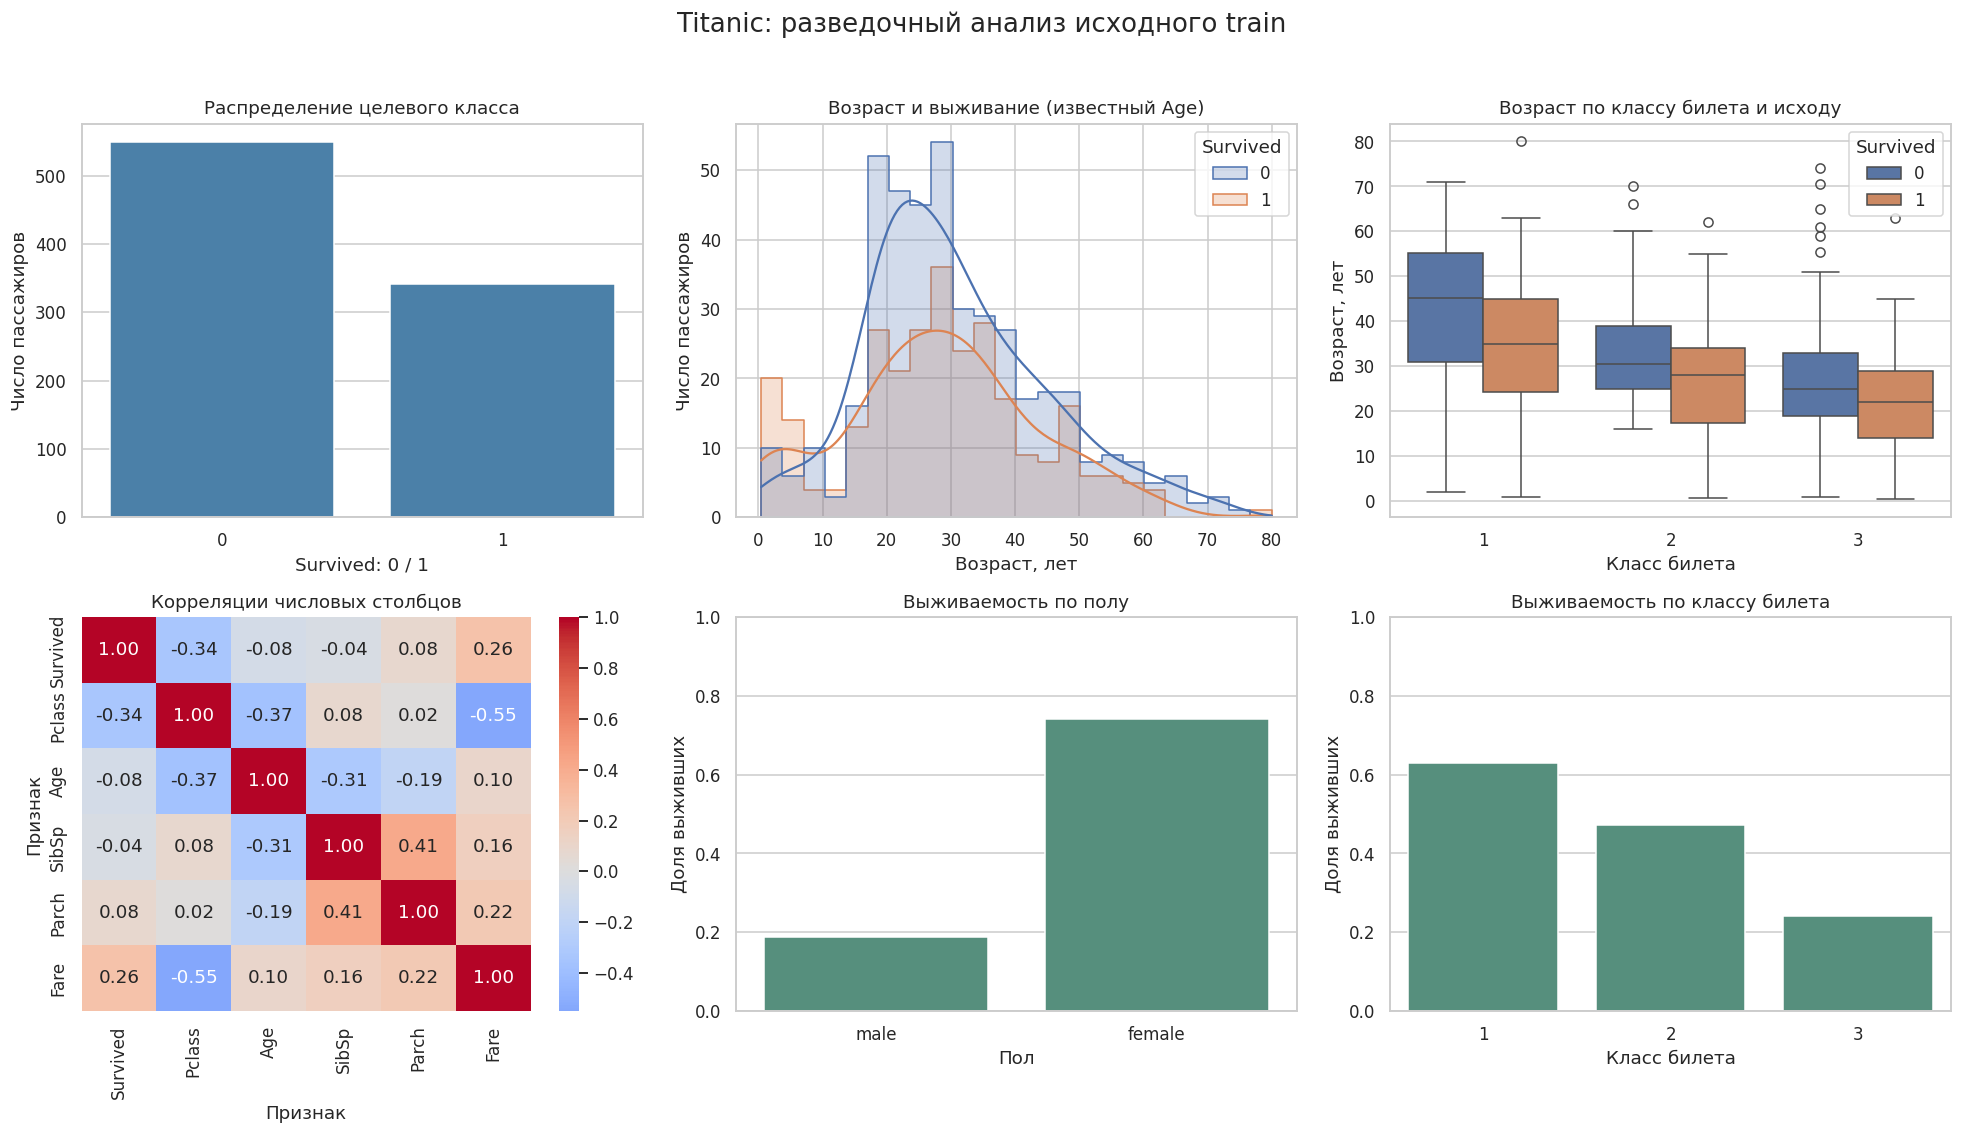

In [3]:
numeric_cols = ["Age", "SibSp", "Parch", "Fare"]  # Исключаем технический ID из анализа формы распределений.
moments = pd.DataFrame({"Асимметрия": train_df[numeric_cols].skew(),
                        "Эксцесс": train_df[numeric_cols].kurtosis()})  # Оцениваем скошенность и тяжесть хвостов.
display(moments.round(3))  # Выводим обе статистики в одной таблице.
for name in ["Survived", "Pclass", "Sex", "Embarked"]:  # Проверяем частоты категорий.
    print(f"\n{name}:\n{train_df[name].value_counts(dropna=False)}")  # Пропуски не скрываем.
family_raw = train_df["SibSp"] + train_df["Parch"] + 1  # Создаём EDA-признак без обучения параметров.
fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))  # Размещаем шесть обязательных видов графиков.
sns.countplot(data=train_df, x="Survived", color="#3b82b8", ax=axes[0, 0])  # Показываем баланс классов.
axes[0, 0].set(title="Распределение целевого класса", xlabel="Survived: 0 / 1", ylabel="Число пассажиров")  # Подписываем оси.
sns.histplot(data=train_df, x="Age", hue="Survived", bins=24, kde=True, element="step", ax=axes[0, 1])  # Сравниваем возраст по классам.
axes[0, 1].set(title="Возраст и выживание (известный Age)", xlabel="Возраст, лет", ylabel="Число пассажиров")  # Указываем единицы.
sns.boxplot(data=train_df, x="Pclass", y="Age", hue="Survived", ax=axes[0, 2])  # Сравниваем возраст внутри классов билета.
axes[0, 2].set(title="Возраст по классу билета и исходу", xlabel="Класс билета", ylabel="Возраст, лет")  # Подписываем категориальную ось.
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]  # Не смешиваем ID с содержательными признаками.
sns.heatmap(train_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 0])  # Показываем парные корреляции.
axes[1, 0].set(title="Корреляции числовых столбцов", xlabel="Признак", ylabel="Признак")  # Указываем смысл шкал.
sns.barplot(data=train_df, x="Sex", y="Survived", errorbar=None, color="#4c9981", ax=axes[1, 1])  # Считаем наблюдаемую долю выживших.
axes[1, 1].set(title="Выживаемость по полу", xlabel="Пол", ylabel="Доля выживших", ylim=(0, 1))  # Общая шкала долей.
sns.barplot(data=train_df, x="Pclass", y="Survived", errorbar=None, color="#4c9981", ax=axes[1, 2])  # Сравниваем класс билета.
axes[1, 2].set(title="Выживаемость по классу билета", xlabel="Класс билета", ylabel="Доля выживших", ylim=(0, 1))  # Фиксируем оси.
fig.suptitle("Titanic: разведочный анализ исходного train", fontsize=17)  # Даём общий заголовок.
fig.tight_layout(rect=[0, 0, 1, 0.96])  # Предотвращаем наложение подписей.
fig.savefig("examples/eda_plots.png", bbox_inches="tight")  # Сохраняем обязательный набор графиков.
plt.show()  # Включаем визуализации в выполненный ноутбук.

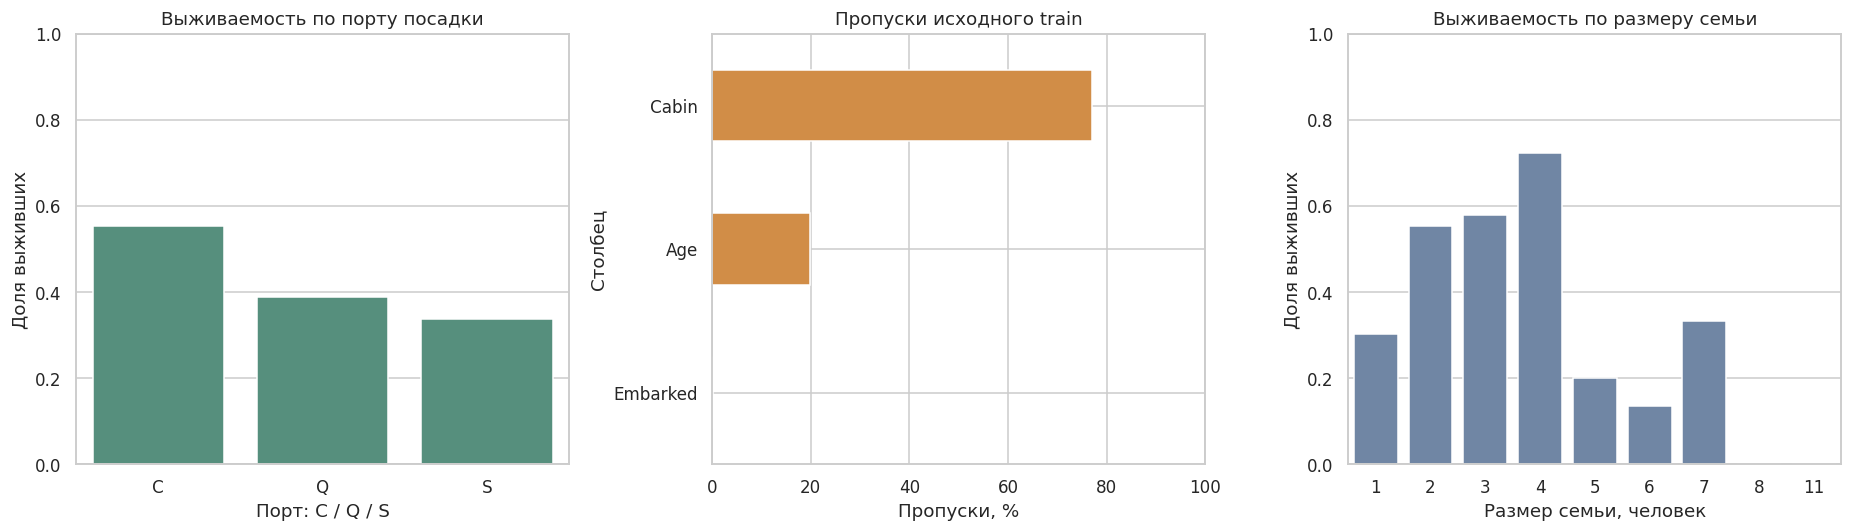

,count,mean
Family_Size,,
1,537,0.303538
2,161,0.552795
3,102,0.578431
4,29,0.724138
5,15,0.200000
6,22,0.136364
7,12,0.333333
8,6,0.000000
11,7,0.000000


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # Добавляем порт, пропуски и размер семьи.
sns.barplot(data=train_df, x="Embarked", y="Survived", order=["C", "Q", "S"], errorbar=None, color="#4c9981", ax=axes[0])  # Сравниваем порты.
axes[0].set(title="Выживаемость по порту посадки", xlabel="Порт: C / Q / S", ylabel="Доля выживших", ylim=(0, 1))  # Подписываем доли.
missing_pct = (missing[missing > 0] / len(train_df) * 100).sort_values()  # Берём столбцы с пропусками.
missing_pct.plot.barh(ax=axes[1], color="#d18d47")  # Делаем пропуски видимыми.
axes[1].set(title="Пропуски исходного train", xlabel="Пропуски, %", ylabel="Столбец", xlim=(0, 100))  # Проценты на единой шкале.
family_view = train_df.assign(Family_Size=family_raw)  # Не изменяем исходную таблицу.
sns.barplot(data=family_view, x="Family_Size", y="Survived", errorbar=None, color="#6785ad", ax=axes[2])  # Проверяем связь семьи с исходом.
axes[2].set(title="Выживаемость по размеру семьи", xlabel="Размер семьи, человек", ylabel="Доля выживших", ylim=(0, 1))  # Подписываем единицы.
fig.tight_layout()  # Проверяем отступы между тремя панелями.
fig.savefig("examples/eda_context.png", bbox_inches="tight")  # Сохраняем дополнительные графики.
plt.show()  # Отображаем их в отчёте.
display(family_view.groupby("Family_Size")["Survived"].agg(["count", "mean"]))  # Показываем численность редких групп.

### Выводы по графикам и статистикам

Класс 0 преобладает, но дисбаланс умеренный. Женщины и пассажиры первого класса
выживали заметно чаще. В Cherbourg наблюдается большая доля выживших, однако
она может быть связана с составом пассажиров по полу и классу билета.
У Fare длинный правый хвост, поэтому среднее плохо описывает типичную стоимость;
редкие дорогие билеты не удаляю как заведомые ошибки. Корреляция не выявляет
все нелинейные связи, а Pclass имеет обратную нумерацию: большее число означает
более низкий класс билета. Большие семьи редки, поэтому их доли нестабильны.

**Обработка пропусков:** Age заполняю медианой по `(Pclass, Sex)`, с общей
медианой как резервом; медиана устойчива к крайним возрастам. Embarked заполняю
модой, потому что пропусков только два. Cabin исключаю: отсутствует более 77%
значений; индикатор известной каюты можно рассмотреть в будущем. Fare заполняю
медианой обучающей части: это потребуется для одного пассажира Kaggle test.

`Family_Size` и `Is_Alone` отражают семейное окружение. `Age_Group` создаётся
фиксированными интервалами для EDA, в модель входит непрерывный Age.
Sex кодируется сохранённым LabelEncoder (**female=0, male=1**), порт — через
`pd.get_dummies`, с категорией C в качестве базы. Полная функция обработки
находится в `titanic_utils.py` и приведена в приложении. Исходный Embarked
сохраняется, поэтому повторный запуск не вызывает `KeyError`.

In [5]:
raw_features = train_df.drop(columns="Survived")  # Исключаем целевую переменную до любых преобразований.
target = train_df["Survived"].astype(int)  # Явно задаём бинарный тип ответа.
raw_train, raw_valid, y_train, y_valid = train_test_split(raw_features, target, test_size=0.2,
                                                       stratify=target, random_state=42)  # Делим сырые данные.
preprocessor = fit_preprocessor(raw_train)  # Медианы, мода и encoder видят только 712 строк.
feature_cols = list(FEATURE_COLS)  # Фиксируем порядок десяти признаков.
prepared_train, X_train = transform_passengers(raw_train, preprocessor, feature_cols)  # Обрабатываем train.
prepared_valid, X_valid = transform_passengers(raw_valid, preprocessor, feature_cols)  # Не обучаем параметры на validation.
prepared_all, X_all = transform_passengers(raw_features, preprocessor, feature_cols)  # Матрица для описания и контроля.
prepared_test, X_kaggle = transform_passengers(test_df, preprocessor, feature_cols)  # Та же схема для Kaggle test.
le_sex = preprocessor["le_sex"]  # Используем именно обученный кодировщик.
print("Train / validation / Kaggle:", X_train.shape, X_valid.shape, X_kaggle.shape)  # Проверяем размеры.
print("Sex mapping:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))  # Исключаем инверсию пола.
print("Age medians:", preprocessor["age_medians"])  # Показываем фактические параметры заполнения.
display(prepared_train[["Age", "Age_Group", "Family_Size", "Is_Alone", "Sex_Encoded", "Embarked"]].head())  # Проверяем новые признаки.
display(prepared_train["Age_Group"].value_counts(sort=False))  # Проверяем фиксированные возрастные группы.
assert preprocessor["fit_rows"] == 712 and len(X_valid) == 179  # Защищаем границу обучения и оценки.
assert list(X_train.columns) == list(X_kaggle.columns) == feature_cols  # Схема одинакова для любых данных.
assert not set(raw_train.index).intersection(raw_valid.index)  # Обучающая и отложенная части не пересекаются.
X_all.assign(Survived=target).to_csv("data/titanic_preprocessed.csv", index=False)  # Сохраняем заново рассчитанный результат.

Train / validation / Kaggle: (712, 10) (179, 10) (418, 10)
Sex mapping: {'female': np.int64(0), 'male': np.int64(1)}
Age medians: {(1, 'female'): 35.0, (1, 'male'): 40.0, (2, 'female'): 29.0, (2, 'male'): 30.0, (3, 'female'): 21.5, (3, 'male'): 26.0}


,Age,Age_Group,Family_Size,Is_Alone,Sex_Encoded,Embarked
692,26.0,19-35,1,1,1,S
481,30.0,19-35,1,1,1,S
527,40.0,36-60,1,1,1,S
855,18.0,13-18,2,0,0,S
801,31.0,19-35,3,0,0,S


Age_Group
0-12      55
13-18     53
19-35    403
36-60    185
61+       16
Name: count, dtype: int64

### Проверка подготовки

После преобразования в матрицах нет пропусков и бесконечностей, порядок
столбцов совпадает. В `Sex_Encoded` значение 1 означает **мужчину**; при ручной
обратной кодировке прогноз был бы неверен. Подготовленная полная таблица
сохраняется для просмотра, но модель обучается только по `X_train`.

## 6. Построение и обучение моделей

Logistic Regression — интерпретируемая линейная модель с L2-регуляризацией,
`C=1`, `max_iter=1000`. Decision Tree может описать нелинейные правила;
`max_depth=5`, `min_samples_split=5`, `min_samples_leaf=2` ограничивают
переобучение. Random Forest добавлен как бонус: 300 деревьев, `max_depth=6`,
`min_samples_leaf=2`. Все случайные состояния фиксируются числом 42.
StandardScaler обучается только на `X_train` и применяется только к LR.

In [6]:
scaler = StandardScaler()  # Оцениваем средние и стандартные отклонения без validation.
X_train_scaled = scaler.fit_transform(X_train)  # Fit выполняется только на обучающей части.
X_valid_scaled = scaler.transform(X_valid)  # Validation использует сохранённый масштаб.
lr_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)  # L2-регуляризация задана по умолчанию.
dt_model = DecisionTreeClassifier(max_depth=5, min_samples_split=5, min_samples_leaf=2, random_state=42)  # Ограничиваем дерево.
rf_model = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2, random_state=42, n_jobs=1)  # Бонусная модель.
models = {"logistic_regression": lr_model, "decision_tree": dt_model, "random_forest": rf_model}  # Сохраняем понятные ключи.
model_names = {"logistic_regression": "Logistic Regression", "decision_tree": "Decision Tree", "random_forest": "Random Forest"}  # Подписи отчёта.
train_times = {}  # Измеряем fit каждой модели отдельно от подготовки признаков.
for key, model in models.items():  # Условия оценки у моделей одинаковые.
    started = perf_counter()  # Фиксируем момент начала обучения.
    model.fit(X_train_scaled if key == "logistic_regression" else X_train, y_train)  # Деревья не масштабируем.
    train_times[key] = perf_counter() - started  # Получаем реальное время на этой машине.
training_summary = pd.DataFrame({"Модель": model_names, "Время fit, с": train_times})  # Сводим измерения.
training_summary["Масштабирование"] = ["StandardScaler", "Нет", "Нет"]  # Указываем различия предобработки.
display(training_summary)  # Показываем фактическое время обучения.

,Модель,"Время fit, с",Масштабирование
logistic_regression,Logistic Regression,0.014832,StandardScaler
decision_tree,Decision Tree,0.006472,Нет
random_forest,Random Forest,0.276096,Нет


### Результат обучения

Все три модели обучены на одной и той же части из 712 пассажиров. Время зависит
от машины и при повторном запуске изменится. Ограничения дерева заданы заранее;
качество ещё не оценивалось при выборе их значений.

## 7. Оценка качества

Ниже приведены пять метрик на 179 отложенных пассажирах при пороге 0.5.
ROC-AUC рассчитывается по `predict_proba`. Дополнительно сравниваю train и
validation, чтобы обнаружить переобучение, и показываю классификационные отчёты.

In [7]:
metrics, validation_probabilities, validation_predictions = {}, {}, {}  # Собираем все результаты оценки.
for key, model in models.items():  # Оцениваем каждую модель одинаковыми функциями.
    train_input = X_train_scaled if key == "logistic_regression" else X_train  # Выбираем нужный масштаб.
    valid_input = X_valid_scaled if key == "logistic_regression" else X_valid  # Не используем fit на validation.
    pred = model.predict(valid_input)  # Получаем классы для Accuracy, Precision, Recall и F1.
    proba = model.predict_proba(valid_input)[:, 1]  # Для ROC-AUC используем вероятность класса 1.
    validation_predictions[key], validation_probabilities[key] = pred, proba  # Переиспользуем одни и те же ответы.
    metrics[key] = {"accuracy": float(accuracy_score(y_valid, pred)),
                    "precision": float(precision_score(y_valid, pred, zero_division=0)),
                    "recall": float(recall_score(y_valid, pred, zero_division=0)),
                    "f1": float(f1_score(y_valid, pred, zero_division=0)),
                    "roc_auc": float(roc_auc_score(y_valid, proba)),
                    "train_roc_auc": float(roc_auc_score(y_train, model.predict_proba(train_input)[:, 1])),
                    "train_accuracy": float(accuracy_score(y_train, model.predict(train_input))),
                    "training_time_sec": float(train_times[key]),
                    "confusion_matrix": confusion_matrix(y_valid, pred, labels=[0, 1]).tolist()}  # Сохраняем численные результаты.
    print(model_names[key])  # Отделяем отчёты моделей.
    print(classification_report(y_valid, pred, target_names=["Не выжил", "Выжил"], digits=4, zero_division=0))  # Показываем support.
metric_frame = pd.DataFrame(metrics).T  # Формируем сравнение без ручного переписывания чисел.
display(metric_frame[["accuracy", "precision", "recall", "f1", "roc_auc", "training_time_sec"]].astype(float).round(4))  # Пять метрик и время.
display(metric_frame[["train_accuracy", "accuracy", "train_roc_auc", "roc_auc"]].astype(float).round(4))  # Проверяем разрыв train/validation.
majority = int(y_train.mode().iloc[0])  # Наивная модель выбирает частый класс только по train.
print("Majority baseline accuracy:", accuracy_score(y_valid, np.full(len(y_valid), majority)))  # База для сравнения Accuracy.
best_key = max(metrics, key=lambda name: metrics[name]["roc_auc"])  # Выбираем лидера сравнения по заранее заданной метрике.
print("Лидер сравнения:", model_names[best_key])  # Это оценка на одном разбиении, не доказательство общего превосходства.
diagnostic_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)  # Отдельно проверяем неограниченное дерево.
diagnostic = {"train_auc": float(roc_auc_score(y_train, diagnostic_tree.predict_proba(X_train)[:, 1])),
               "valid_auc": float(roc_auc_score(y_valid, diagnostic_tree.predict_proba(X_valid)[:, 1]))}  # Не выбираем параметры по этому сравнению.
print("Неограниченное дерево (диагностика):", diagnostic)  # Численно демонстрируем риск переобучения.

Logistic Regression
              precision    recall  f1-score   support

    Не выжил     0.8151    0.8818    0.8472       110
       Выжил     0.7833    0.6812    0.7287        69

    accuracy                         0.8045       179
   macro avg     0.7992    0.7815    0.7879       179
weighted avg     0.8029    0.8045    0.8015       179

Decision Tree
              precision    recall  f1-score   support

    Не выжил     0.8034    0.8545    0.8282       110
       Выжил     0.7419    0.6667    0.7023        69

    accuracy                         0.7821       179
   macro avg     0.7727    0.7606    0.7652       179
weighted avg     0.7797    0.7821    0.7797       179

Random Forest
              precision    recall  f1-score   support

    Не выжил     0.7907    0.9273    0.8536       110
       Выжил     0.8400    0.6087    0.7059        69

    accuracy                         0.8045       179
   macro avg     0.8153    0.7680    0.7797       179
weighted avg     0.8097   

,accuracy,precision,recall,f1,roc_auc,training_time_sec
logistic_regression,0.8045,0.7833,0.6812,0.7287,0.8489,0.0148
decision_tree,0.7821,0.7419,0.6667,0.7023,0.8132,0.0065
random_forest,0.8045,0.8400,0.6087,0.7059,0.8482,0.2761


,train_accuracy,accuracy,train_roc_auc,roc_auc
logistic_regression,0.8090,0.8045,0.8627,0.8489
decision_tree,0.8525,0.7821,0.9069,0.8132
random_forest,0.8778,0.8045,0.9342,0.8482


Majority baseline accuracy: 0.6145251396648045
Лидер сравнения: Logistic Regression
Неограниченное дерево (диагностика): {'train_auc': 0.9993032783465585, 'valid_auc': 0.7682476943346508}


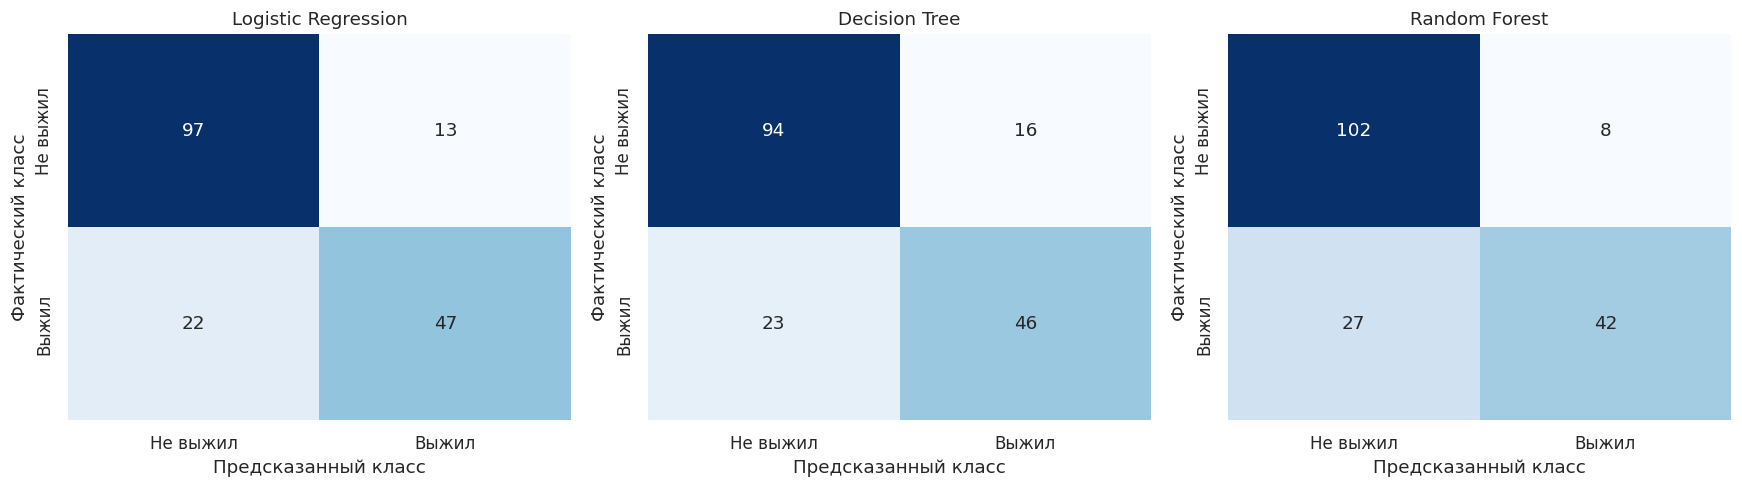

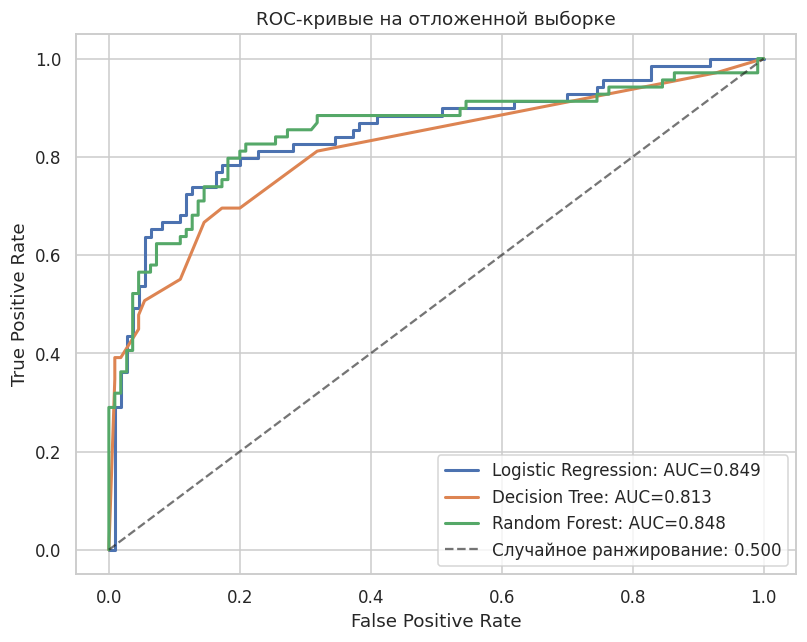

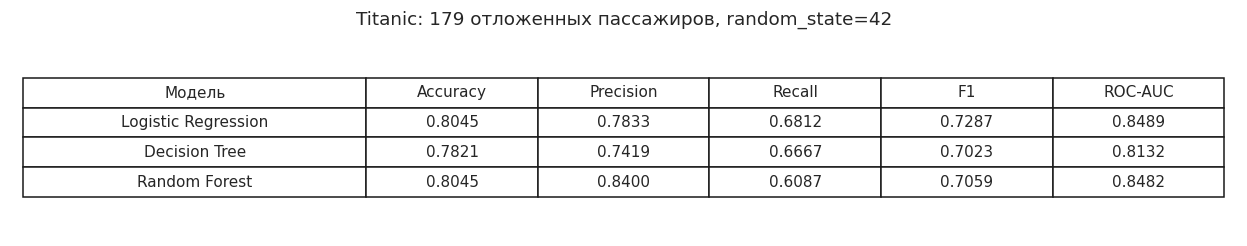

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))  # Строим отдельную матрицу для каждой модели.
for ax, key in zip(axes, models):  # Порядок совпадает с таблицей метрик.
    sns.heatmap(np.array(metrics[key]["confusion_matrix"]), annot=True, fmt="d", cbar=False, cmap="Blues",
                xticklabels=["Не выжил", "Выжил"], yticklabels=["Не выжил", "Выжил"], ax=ax)  # Указываем оба класса.
    ax.set(title=model_names[key], xlabel="Предсказанный класс", ylabel="Фактический класс")  # Не путаем направления ошибок.
fig.tight_layout()  # Убираем наложения названий и осей.
fig.savefig("examples/confusion_matrices.png", bbox_inches="tight")  # Сохраняем матрицы в структуре задания.
plt.show()  # Добавляем матрицы к выполненным выводам.
fig, ax = plt.subplots(figsize=(7.5, 6))  # Все ROC-кривые показываем на общей шкале.
for key in models:  # Сравниваем ранжирование одинаковых пассажиров.
    fpr, tpr, _ = roc_curve(y_valid, validation_probabilities[key])  # Порог меняется вдоль кривой.
    ax.plot(fpr, tpr, lw=2, label=f"{model_names[key]}: AUC={metrics[key]['roc_auc']:.3f}")  # Подписываем фактический AUC.
ax.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Случайное ранжирование: 0.500")  # Добавляем опорную диагональ.
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC-кривые на отложенной выборке")  # Указываем выборку.
ax.legend(loc="lower right")  # Легенда не перекрывает основные части кривых.
fig.tight_layout()  # Проверяем расположение подписей.
fig.savefig("examples/roc_curves.png", bbox_inches="tight")  # Сохраняем обязательный ROC-график.
plt.show()  # Включаем кривые в отчёт.
table_data = [[model_names[k]] + [f"{metrics[k][m]:.4f}" for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]] for k in models]  # Готовим изображение метрик для LMS.
fig, ax = plt.subplots(figsize=(11.5, 2.4))  # Читаемый размер таблицы для отдельного изображения.
ax.axis("off")  # Убираем оси у таблицы.
table = ax.table(cellText=table_data, colLabels=["Модель", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"], cellLoc="center", loc="center", colWidths=[0.28, 0.14, 0.14, 0.14, 0.14, 0.14])  # Показываем ровно пять метрик.
table.auto_set_font_size(False)  # Размер шрифта не зависит от автоматической подгонки.
table.set_fontsize(10)  # Сохраняем читаемость чисел.
table.scale(1, 1.7)  # Добавляем высоту строк.
ax.set_title("Titanic: 179 отложенных пассажиров, random_state=42", pad=10)  # Указываем условия расчёта.
fig.tight_layout()  # Не обрезаем заголовок.
fig.savefig("examples/metrics_table.png", bbox_inches="tight")  # Отдельное изображение таблицы метрик.
plt.show()  # Отображаем ту же таблицу в ноутбуке.

### Анализ качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | Время fit, с |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8045 | 0.7833 | 0.6812 | 0.7287 | 0.8489 | 0.0148 |
| Decision Tree | 0.7821 | 0.7419 | 0.6667 | 0.7023 | 0.8132 | 0.0065 |
| Random Forest | 0.8045 | 0.8400 | 0.6087 | 0.7059 | 0.8482 | 0.2761 |


На этом разбиении лидер по ROC-AUC — **Logistic Regression (0.8489)**.
Accuracy наивного прогноза большинства равна 110/179 = **0.6145**;
все три модели превосходят эту базу. Цель ROC-AUC ≥ 0.80
достигнута всеми тремя моделями.

У ограниченного дерева train ROC-AUC = 0.9069,
validation ROC-AUC = 0.8132; разрыв равен
0.0936. Для отдельного неограниченного дерева
соответствующие значения — 0.9993 и 0.7682.
Это показывает, почему идеальный результат на train не означает хорошего
обобщения. Ограничение глубины уменьшает свободу дерева, но не устраняет
неопределённость оценки на небольшой выборке.

Precision лидера = 0.7833, Recall = 0.6812:
доля верных положительных прогнозов выше доли найденных выживших; модель пропускает часть класса 1.
Его матрица ошибок имеет TN=97,
FP=13, FN=22,
TP=47. Порог 0.5 фиксирован заранее.

Сравнение трёх моделей и выбор лидера выполнены на одном validation;
оценка выбранного победителя может быть оптимистичной. Для более устойчивого
вывода нужна вложенная или отдельная кросс-валидация с обучением всех
преобразований внутри каждого фолда. Результат не является Kaggle score.

## 8. Интерпретация результатов

Коэффициенты LR относятся к стандартизованным признакам: положительный знак
увеличивает логарифм шансов класса 1, отрицательный уменьшает. Для `Sex_Encoded`
положительное изменение означает переход от female=0 к male=1. Важность дерева
отражает снижение неоднородности при разбиениях, а не направление влияния.

,Feature,Coefficient
1,Sex_Encoded,-1.222809
0,Pclass,-0.967947
2,Age,-0.556019
3,SibSp,-0.295030
7,Is_Alone,-0.283719
6,Family_Size,-0.224116
9,Embarked_S,-0.130004
4,Parch,-0.051526
5,Fare,0.077828
8,Embarked_Q,0.089916


,Feature,Importance
1,Sex_Encoded,0.547662
0,Pclass,0.186186
5,Fare,0.105210
2,Age,0.099922
6,Family_Size,0.056601
4,Parch,0.002740
3,SibSp,0.001678
7,Is_Alone,0.000000
8,Embarked_Q,0.000000
9,Embarked_S,0.000000


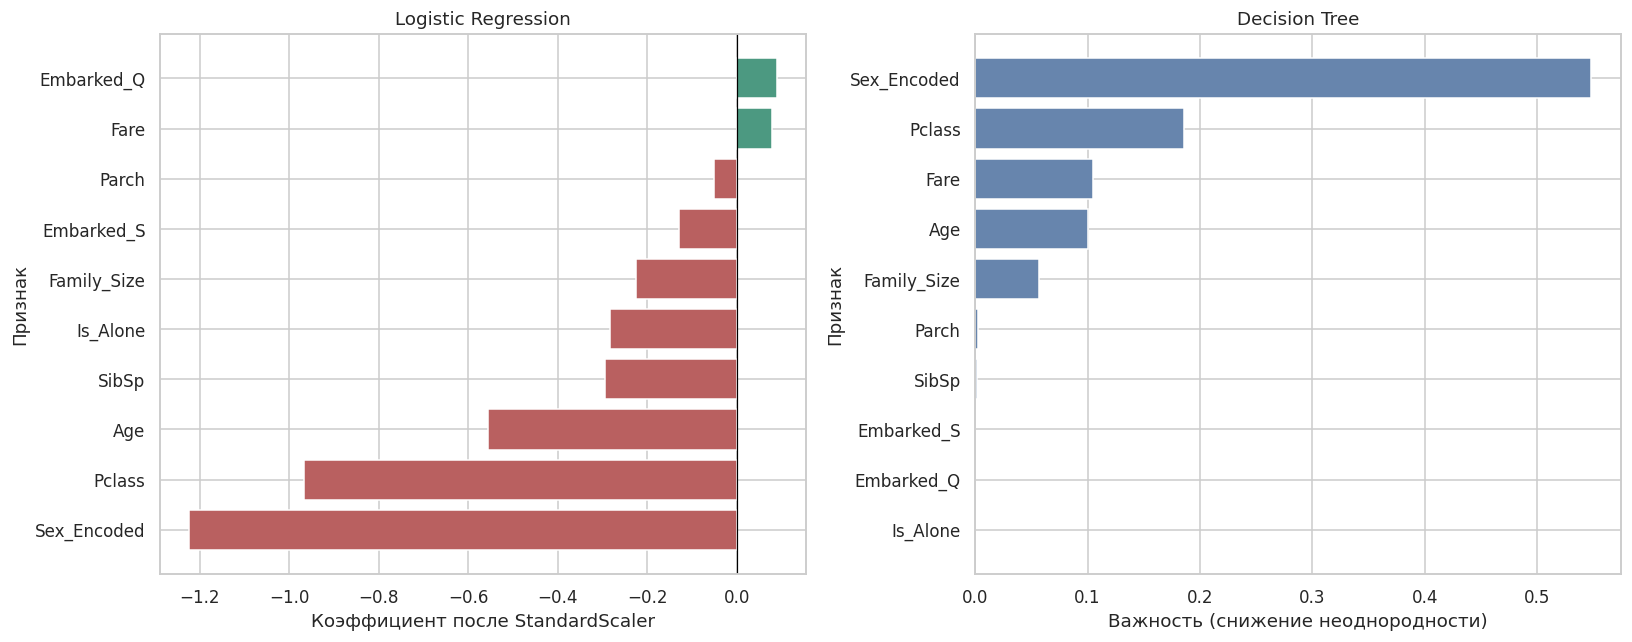

,count,mean
Sex,,
female,314,0.742038
male,577,0.188908


,count,mean
Pclass,,
1,216,0.629630
2,184,0.472826
3,491,0.242363


,count,mean
Is_Alone,,
0,354,0.505650
1,537,0.303538


,count,mean
Embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957


2553

In [9]:
coefficients = pd.DataFrame({"Feature": feature_cols, "Coefficient": lr_model.coef_[0]})  # Собираем веса LR.
coefficients = coefficients.sort_values("Coefficient")  # Упорядочиваем по знаку и величине.
importances = pd.DataFrame({"Feature": feature_cols, "Importance": dt_model.feature_importances_})  # Берём важность дерева.
importances = importances.sort_values("Importance", ascending=False)  # Выделяем ведущие признаки.
display(coefficients)  # Сохраняем точные коэффициенты в выводах.
display(importances)  # Показываем все признаки, включая нулевые важности.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))  # Сравниваем две формы интерпретации.
axes[0].barh(coefficients["Feature"], coefficients["Coefficient"], color=["#b96060" if x < 0 else "#4c9981" for x in coefficients["Coefficient"]])  # Цвет кодирует знак.
axes[0].axvline(0, color="black", lw=0.8)  # Отмечаем отсутствие линейного эффекта.
axes[0].set(title="Logistic Regression", xlabel="Коэффициент после StandardScaler", ylabel="Признак")  # Указываем масштаб.
sorted_importance = importances.sort_values("Importance")  # Располагаем важные признаки сверху.
axes[1].barh(sorted_importance["Feature"], sorted_importance["Importance"], color="#6785ad")  # Показываем вклад разбиений дерева.
axes[1].set(title="Decision Tree", xlabel="Важность (снижение неоднородности)", ylabel="Признак")  # Не приписываем знака важности.
fig.tight_layout()  # Вмещаем имена всех десяти признаков.
fig.savefig("examples/feature_importance.png", bbox_inches="tight")  # Сохраняем интерпретацию.
plt.show()  # Показываем графики в отчёте.
insights = {}  # Сохраняем описательные наблюдения для Markdown-выводов.
observed = train_df.assign(Family_Size=family_raw, Is_Alone=(family_raw == 1).astype(int))  # Не заполняем пропуски для исходных группировок.
for column in ["Sex", "Pclass", "Is_Alone", "Embarked"]:  # Рассматриваем четыре содержательных аспекта.
    grouped = observed.groupby(column)["Survived"].agg(["count", "mean"])  # Указываем и размер группы, и долю.
    display(grouped)  # Проверяем, на скольких наблюдениях основан вывод.
    insights[column] = {str(k): {"count": int(row["count"]), "rate": float(row["mean"])} for k, row in grouped.iterrows()}  # Записываем факты.
Path("models/interpretation.json").write_text(json.dumps({"coefficients": coefficients.to_dict("records"),
    "importances": importances.to_dict("records"), "insights": insights}, ensure_ascii=False, indent=2), encoding="utf-8")  # Пояснения опираются на вычисления.

### Интерпретация коэффициентов и наблюдаемых связей

| Направление | Признак | Коэффициент |
|---|---|---:|
| Повышает логарифм шансов | Embarked_Q | +0.0899 |
| Повышает логарифм шансов | Fare | +0.0778 |
| Понижает логарифм шансов | Sex_Encoded | -1.2228 |
| Понижает логарифм шансов | Pclass | -0.9679 |
| Понижает логарифм шансов | Age | -0.5560 |


Крупнейшие важности дерева: **Sex_Encoded (0.548), Pclass (0.186), Fare (0.105)**.
Положительных коэффициентов в этой модели только два; третий положительный
эффект не добавляется искусственно ради списка из трёх признаков.
Коэффициент `Sex_Encoded` относится к мужскому полу, поскольку male=1.
Коэффициенты показывают условный линейный эффект после стандартизации,
а важности дерева не показывают его направление. Признаки `Family_Size`,
`SibSp` и `Parch` линейно зависимы, поэтому их отдельные веса не следует
трактовать как независимые эффекты. Коррелированные признаки делят важность
между собой; высокая важность также не доказывает причинного влияния.

Наблюдения для всего исходного train:

1. Выживаемость женщин — **74.2%**
   (n=314), мужчин — **18.9%**
   (n=577). Пол сильно связан с исходом в этих исторических данных.
2. Первый класс — **63.0%**,
   третий — **24.2%**. Класс билета может отражать
   расположение кают и доступ к эвакуации, но причинный механизм здесь не проверялся.
3. Одиночные пассажиры — **30.4%**,
   пассажиры с родственниками — **50.6%**.
   У очень больших семей наблюдений мало; групповые доли нельзя считать универсальным правилом.
4. Порт C — **55.4%**, Q — **39.0%**,
   S — **33.7%**. Различия могут объясняться составом групп;
   две строки с неизвестным портом не включены в эту группировку.

Практический смысл анализа — выявить полезные признаки и группы ошибок
учебной модели. По этим наблюдениям нельзя делать выводы о риске для современных
пассажиров или автоматически переносить исторические связи на другие условия.

## 9. Функция предсказания

`predict_passenger(passenger_data, model, scaler, feature_cols,
use_scaling=True, preprocessor=...)` возвращает пару `(prediction, probability)`.
Функция создаёт новые признаки, применяет сохранённое кодирование и проверяет
входные значения. Входной словарь не изменяется. Полный исходный код функции
и интерактивного режима расположен в приложении и `titanic_utils.py`.

Первые пять профилей взяты из условий задания. У них нет известных фактических
исходов, поэтому указанные в задании «ожидания» — иллюстрации, а не истинная
разметка. Расхождение с ожиданием не является измеренной ошибкой классификации.
Шестой пример дополнительно проверяет заполнение пропущенных Age и Fare.

In [10]:
demo_passengers = [  # Используем пять обязательных разнообразных профилей.
    {"Pclass": 1, "Sex": "female", "Age": 25, "SibSp": 1, "Parch": 0, "Fare": 100, "Embarked": "C"},
    {"Pclass": 3, "Sex": "male", "Age": 30, "SibSp": 0, "Parch": 0, "Fare": 7.25, "Embarked": "S"},
    {"Pclass": 2, "Sex": "female", "Age": 5, "SibSp": 3, "Parch": 1, "Fare": 30, "Embarked": "S"},
    {"Pclass": 1, "Sex": "male", "Age": 60, "SibSp": 0, "Parch": 0, "Fare": 200, "Embarked": "C"},
    {"Pclass": 3, "Sex": "female", "Age": 22, "SibSp": 0, "Parch": 0, "Fare": 8, "Embarked": "Q"},
    {"Pclass": 3, "Sex": "male", "Age": None, "SibSp": 0, "Parch": 0, "Fare": None, "Embarked": None},
]
demo_rows = []  # Для каждого пассажира показываем вход и оба обязательных прогноза.
for number, passenger in enumerate(demo_passengers, start=1):  # Индексация понятна читателю отчёта.
    before = passenger.copy()  # Проверяем отсутствие изменения пользовательского словаря.
    lr_result = predict_passenger(passenger, lr_model, scaler, feature_cols, preprocessor=preprocessor)  # LR с масштабированием.
    dt_result = predict_passenger(passenger, dt_model, None, feature_cols, use_scaling=False, preprocessor=preprocessor)  # DT без масштаба.
    assert passenger == before  # Повторное использование словаря безопасно.
    demo_rows.append({"Пример": number, **passenger, "LR": lr_result[0], "LR, %": lr_result[1] * 100,
                      "DT": dt_result[0], "DT, %": dt_result[1] * 100, "Совпадают": lr_result[0] == dt_result[0]})  # Сохраняем вероятности.
demo_results = pd.DataFrame(demo_rows)  # Одна строка содержит полный результат одного примера.
display(demo_results.round(2))  # Вероятности представлены в процентах.
demo_results.to_csv("examples/prediction_examples.csv", index=False)  # Позволяем отдельно изучить примеры.
RUN_INTERACTIVE = False  # Run All не должен зависеть от ручного ввода.
if RUN_INTERACTIVE:  # Для самостоятельного запуска замените False на True.
    interactive_predict(lr_model, scaler, feature_cols, preprocessor)  # Вызываем тот же проверенный инференс.

,Пример,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,LR,"LR, %",DT,"DT, %",Совпадают
0,1,1,female,25.0,1,0,100.00,C,1,96.10,1,100.00,True
1,2,3,male,30.0,0,0,7.25,S,0,7.66,0,11.00,True
2,3,2,female,5.0,3,1,30.00,S,1,80.72,1,100.00,True
3,4,1,male,60.0,0,0,200.00,C,0,30.64,0,30.91,True
4,5,3,female,22.0,0,0,8.00,Q,1,73.70,1,53.49,True
5,6,3,male,NaN,0,0,NaN,None,0,9.03,0,11.00,True


### Разбор демонстрационных прогнозов

Модели совпали на всех шести профилях.
На первых пяти профилях оба алгоритма совпали с иллюстративными ожиданиями задания.
Это не измерение ошибки: настоящих меток у синтетических профилей нет.
LR суммирует плавные линейные эффекты, а DT относит пассажира к листу дерева,
поэтому вероятности и классы могут различаться. Совпадение моделей само по себе
не гарантирует правильность. При расхождении нужно изучить похожие наблюдения
и правила дерева, а не заменять прогноз желаемым ответом.

Шестой профиль успешно обработан с пропущенными Age, Fare и Embarked.
Параметры заполнения взяты из обучающей части; `predict_passenger` не вызывает
`fit` и не меняет исходные словари. Интерактивный режим реализован, но его
автоматический запуск отключён, чтобы `Restart & Run All` не ожидал клавиатуру.

## 10. Сохранение модели и вспомогательных объектов

Сохраняю модели, scaler, LabelEncoder, состояние заполнения пропусков, порядок
признаков и метрики. Модели остаются обученными на 712 строках, чтобы сохранённые
объекты точно соответствовали оценке на validation. Повторного обучения на
всех 891 строках после оценки не выполняю.

In [11]:
artifact_objects = {"lr_model": lr_model, "dt_model": dt_model, "rf_model": rf_model,
                    "scaler": scaler, "le_sex": le_sex, "preprocessor": preprocessor}  # Полный комплект преобразований.
for name, obj in artifact_objects.items():  # Сохраняем каждый объект отдельно, как требует задание.
    joblib.dump(obj, f"models/{name}.pkl", compress=3)  # Сжатые модели подходят для загрузки в GitHub.
Path("models/feature_cols.json").write_text(json.dumps(feature_cols, indent=2), encoding="utf-8")  # Порядок входов модели.
Path("models/metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")  # Только фактически полученные метрики.
source_hashes = {name: hashlib.sha256(Path(f"data/{name}").read_bytes()).hexdigest() for name in ["train.csv", "test.csv"]}  # Фиксируем версии данных.
metadata = {"training_date": config["date"], "student": config["student"], "group": config["group"],
            "python_version": platform.python_version(), "sklearn_version": sklearn.__version__,
            "pandas_version": pd.__version__, "numpy_version": np.__version__,
            "random_state": 42, "split": {"train_rows": len(X_train), "validation_rows": len(X_valid), "test_size": 0.2, "stratified": True},
            "train_passenger_ids": raw_train["PassengerId"].astype(int).tolist(),
            "validation_passenger_ids": raw_valid["PassengerId"].astype(int).tolist(),
            "sex_encoding": {str(k): int(v) for k, v in zip(le_sex.classes_, le_sex.transform(le_sex.classes_))},
            "feature_cols": feature_cols, "age_group_used_in_model": False,
            "source_sha256": source_hashes, "model_params": {k: m.get_params() for k, m in models.items()},
            "best_model_on_validation": best_key, "unrestricted_tree_diagnostic": diagnostic,
            "repository_url": config["repository_url"], "github_raw_verified": False,
            "ai_assistance": "OpenAI Codex: код, пояснения, проверки"}  # Сохраняем воспроизводимость и ограничения.
Path("models/metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")  # Метаданные в отдельном JSON.
best_model = models[best_key]  # Для Kaggle используем лидера текущего сравнения.
kaggle_input = scaler.transform(X_kaggle) if best_key == "logistic_regression" else X_kaggle  # Соблюдаем масштаб выбранного алгоритма.
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Survived": best_model.predict(kaggle_input).astype(int)})  # Формат Kaggle.
assert submission.shape == (418, 2) and submission["Survived"].isin([0, 1]).all()  # Проверяем строки и классы.
submission.to_csv("submission.csv", index=False)  # Сохраняем новый прогноз, не меняя исходный submission в папке задания.
print("Артефакты:", sorted(p.name for p in Path("models").iterdir()))  # Проверяем комплектность файлов.
print("Submission:", submission.shape, "выживших:", int(submission["Survived"].sum()))  # Контроль пакетного инференса.
display(submission.head())  # Показываем формат готового файла.

Артефакты: ['dt_model.pkl', 'feature_cols.json', 'interpretation.json', 'le_sex.pkl', 'lr_model.pkl', 'metadata.json', 'metrics.json', 'preprocessor.pkl', 'rf_model.pkl', 'scaler.pkl']
Submission: (418, 2) выживших: 157


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


### Результат сохранения

В `models/` записаны шесть `.pkl`, список признаков и JSON с метриками и
метаданными. `submission.csv` содержит 418 прогнозов. Метрик по этому файлу
нет: правильные ответы Kaggle test в исходных материалах отсутствуют.

## 11. Загрузка модели из репозитория и быстрый инференс

По просьбе автора публикация в GitHub выполняется им самостоятельно.
Сейчас проверяю восстановление локальных моделей без переобучения и совпадение
прогнозов на первых трёх профилях. Реальная загрузка по raw-ссылке включается
после заполнения `student.json` → `repository_url` и повторного запуска ячейки.

`load_artifacts_from_github()` формирует адрес
`https://raw.githubusercontent.com/<owner>/<repo>/main/module-1-titanic`,
проверяет HTTP-статус и загружает согласованный комплект моделей и преобразований.
Загружать `.pkl` следует только из собственного доверенного репозитория:
этот формат допускает выполнение кода при десериализации.

In [12]:
loaded_local = load_local_artifacts("models")  # Восстанавливаем объекты с диска, не вызывая fit.
reload_rows = []  # Проверяем обязательные три профиля для обеих моделей.
for number, passenger in enumerate(demo_passengers[:3], start=1):  # Берём те же данные, что в разделе 9.
    for key, scaling in [("lr_model", True), ("dt_model", False)]:  # Сравниваем LR и DT по отдельности.
        original = lr_model if scaling else dt_model  # Выбираем исходный обученный объект.
        expected = predict_passenger(passenger, original, scaler if scaling else None, feature_cols,
                                     use_scaling=scaling, preprocessor=preprocessor)  # Исходный прогноз.
        actual = predict_passenger(passenger, loaded_local[key], loaded_local["scaler"] if scaling else None,
                                   loaded_local["feature_cols"], use_scaling=scaling,
                                   preprocessor=loaded_local["preprocessor"])  # Прогноз восстановленной модели.
        assert expected[0] == actual[0] and np.isclose(expected[1], actual[1], atol=1e-12, rtol=0)  # Проверяем класс и вероятность.
        reload_rows.append({"Пример": number, "Модель": key, "Класс": actual[0], "Вероятность": actual[1], "Совпадение": True})  # Протокол проверки.
display(pd.DataFrame(reload_rows))  # Шесть успешных сравнений без переобучения.
config = json.loads(Path("student.json").read_text(encoding="utf-8"))  # Подхватываем адрес после публикации.
github_verified = False  # Не объявляем непроведённую сетевую проверку успешной.
if config.get("repository_url"):  # Включаем реальный raw-инференс только при известном адресе.
    loaded_remote = load_artifacts_from_github(config["repository_url"], config.get("branch", "main"))  # Скачиваем свои файлы.
    for passenger in demo_passengers[:3]:  # Повторяем проверку трёх исходных профилей.
        for key, scaling in [("lr_model", True), ("dt_model", False)]:  # Проверяем обе обязательные модели.
            expected = predict_passenger(passenger, loaded_local[key], loaded_local["scaler"] if scaling else None,
                                         feature_cols, use_scaling=scaling, preprocessor=loaded_local["preprocessor"])  # Локальный результат.
            actual = predict_passenger(passenger, loaded_remote[key], loaded_remote["scaler"] if scaling else None,
                                       loaded_remote["feature_cols"], use_scaling=scaling, preprocessor=loaded_remote["preprocessor"])  # Raw-результат.
            assert expected[0] == actual[0] and np.isclose(expected[1], actual[1], atol=1e-12, rtol=0)  # Проверяем совпадение.
    github_verified = True  # Устанавливаем успех только после настоящих запросов и сравнений.
    print("GitHub raw: проверено; BASE_URL =", loaded_remote["base_url"])  # Показываем рабочий источник.
else:  # Отсутствующий адрес не мешает воспроизводимому локальному Run All.
    print("Локальная загрузка: проверена. GitHub raw: не проверен — публикация автором ещё не выполнена.")  # Честный статус.
metadata.update(repository_url=config.get("repository_url"), github_raw_verified=github_verified)  # Сохраняем фактический статус.
Path("models/metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")  # Обновляем метаданные.

,Пример,Модель,Класс,Вероятность,Совпадение
0,1,lr_model,1,0.960966,True
1,1,dt_model,1,1.000000,True
2,2,lr_model,0,0.076616,True
3,2,dt_model,0,0.110032,True
4,3,lr_model,1,0.807211,True
5,3,dt_model,1,1.000000,True


Локальная загрузка: проверена. GitHub raw: не проверен — публикация автором ещё не выполнена.


10466

### Вывод о быстром инференсе

Локально загруженные модели дают те же классы и вероятности, что исходные;
вызовов `fit` при загрузке нет. Публикация и проверка GitHub raw **пока не
выполнены**, поскольку автор будет загружать проект самостоятельно.
Пошаговая инструкция находится в `GITHUB_UPLOAD.md` в корне проекта.

## 12. Выводы

### Что получилось

Проведён EDA с девятью основными панелями, проверены пропуски, категории и
распределения. На едином разбиении обучены обязательные LR и DT, а также
бонусный Random Forest. Лидер по ROC-AUC — **Logistic Regression**:
ROC-AUC **0.8489**, Accuracy **0.8045**,
Precision **0.7833**, Recall **0.6812**,
F1 **0.7287**. Его время fit в выполненном запуске —
**0.0148 с**. Для всех моделей фактическое время
и полный набор метрик сохранены в `models/metrics.json`.

Пол и класс билета связаны с выживанием наиболее заметно; семья и порт также
дают полезную информацию. Реализованы шесть примеров, необязательный ввод
с клавиатуры и пакетный прогноз для 418 пассажиров. Модели и все преобразования
сохранены, локальный инференс после загрузки проверен на трёх профилях.

### Трудности и ограничения

- У Age около 20% пропусков, поэтому часть индивидуальной информации утрачена;
  медиана группы — приближение, а не восстановленный истинный возраст.
- У Cabin более 77% пропусков; столбец удалён. Fare имеет длинный хвост.
- Классы распределены как 61.6% и 38.4%, поэтому одной Accuracy недостаточно.
- Неограниченное дерево показывает train ROC-AUC 0.9993
  против validation 0.7682; присутствует переобучение.
- Оценка основана на одном разбиении; интервал неопределённости и калибровка
  вероятностей не оценивались. Выбор лидера и его оценка используют один validation.
- GitHub-публикация и реальная загрузка по raw-ссылке ещё не выполнены:
  автор будет загружать проект самостоятельно. Код и инструкция подготовлены.

### Возможные улучшения

1. Извлечь обращения Mr/Mrs/Miss/Master из Name и проверить прирост на кросс-валидации.
2. Проверить взаимодействие `Pclass × Sex`, чтобы LR могла описать неодинаковый эффект пола по классам.
3. Добавить `log1p(Fare)` и индикаторы отсутствующих Age/Cabin, проверяя пользу вне обучения.
4. Подобрать глубину дерева, размер листа и C внутри кросс-валидации, не используя внешний validation для подбора.
5. Провести стратифицированную кросс-валидацию с повторной оценкой медиан, кодирования и масштаба в каждом фолде.
6. Оценить калибровку вероятностей и выбрать порог по заранее установленной цене FN и FP.
7. Проверить групповые разбиения по семье или билету: связанные пассажиры могут попадать в разные части случайного split.
8. Сравнить Random Forest с градиентным бустингом при одинаковой процедуре проверки.

Автоматическое балансирование не применялось: дисбаланс умеренный. Если
проверять SMOTE, его следует выполнять только внутри обучающей части каждого
фолда и учитывать категориальные признаки.

## 13. Список использованных источников

1. Материалы преподавателя: «Модуль 1. Введение в Data Science и EDA» и
   «Модуль 1. Data Science (Титаник). Конспект», папка «Теория».
   Использованы для структуры исследования и разбора признаков.
2. Kaggle. [Titanic — Machine Learning from Disaster: Data](https://www.kaggle.com/competitions/titanic/data).
   Источник описания полей; локальные CSV предоставлены вместе с заданием.
3. Scikit-learn. [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html).
   Разделение данных до обучения преобразований и предотвращение утечки.
4. Scikit-learn. [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html).
   Определения метрик и использование вероятностей для ROC-AUC.
5. Pandas. [pandas.get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html).
   One-Hot Encoding и базовая категория.
6. Scikit-learn. [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
   Регуляризация и вероятностный вывод линейной модели.
7. Scikit-learn. [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
   Ограничения глубины и размера листа.
8. Scikit-learn. [Model persistence](https://scikit-learn.org/stable/model_persistence.html).
   Сохранение обученных объектов и совместимость окружения.

Дата обращения к онлайн-документации: 02.11.2026. Версии библиотек фактического
расчёта зафиксированы в `requirements.txt` и `models/metadata.json`.
Исходный пример кода из папки практики использован как учебный ориентир;
предобработка, проверки и структура отчёта переработаны. Использование OpenAI
Codex раскрыто на титульном листе. Готовые Kaggle kernels не копировались.

## 14. Приложение

Ниже полный код отчёта и вспомогательных функций с комментариями. Блоки
разделены маркерами `# %%` (формат Jupytext). ; зависимости находятся в `requirements.txt`.В скрипте используется
backend Agg, поэтому графики сохраняются в файлы без открытия окон.

### Зависимости

```text
numpy==2.2.6
pandas==2.2.3
scipy==1.18.1
matplotlib==3.10.1
seaborn==0.13.2
scikit-learn==1.7.2
joblib==1.5.2
requests==2.32.5
tabulate==0.9.0
nbformat==5.10.4
nbclient==0.10.2
nbconvert==7.16.6
ipykernel==6.30.1
```

### Полный код

```python
# Зависимости (requirements.txt):
# numpy==2.2.6
# pandas==2.2.3
# scipy==1.18.1
# matplotlib==3.10.1
# seaborn==0.13.2
# scikit-learn==1.7.2
# joblib==1.5.2
# requests==2.32.5
# tabulate==0.9.0
# nbformat==5.10.4
# nbclient==0.10.2
# nbconvert==7.16.6
# ipykernel==6.30.1

# %% Настройка запуска самостоятельного скрипта
from pathlib import Path  # Находим папку модуля независимо от текущего каталога.
import os  # Выставляем рабочую папку для относительных путей.
import matplotlib  # В скрипте сохраняем рисунки без графического окна.
matplotlib.use("Agg")  # Ноутбук использует обычный встроенный backend.
os.chdir(Path(__file__).resolve().parent)  # Все данные ищутся внутри модуля.

# %% Общие функции предобработки и инференса
"""Предобработка и инференс для практической работы по Titanic."""

from io import BytesIO  # Читаем скачанные модели без временных файлов.
from pathlib import Path  # Используем переносимые пути к артефактам.
import json  # Читаем список признаков и конфигурацию.
import re  # Проверяем структуру адреса GitHub.

import joblib  # Сохраняем и восстанавливаем обученные объекты.
import numpy as np  # Проверяем конечность числовых значений.
import pandas as pd  # Преобразуем словари пассажиров в таблицы.
import requests  # Загружаем артефакты по raw-ссылкам.
from sklearn.preprocessing import LabelEncoder  # Фиксируем кодировку пола.

FEATURE_COLS = [  # Порядок столбцов одинаков при обучении и инференсе.
    "Pclass", "Sex_Encoded", "Age", "SibSp", "Parch", "Fare",
    "Family_Size", "Is_Alone", "Embarked_Q", "Embarked_S",
]
REQUIRED_FIELDS = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]


def fit_preprocessor(frame):
    """Оцениваем параметры заполнения только по обучающей части."""
    encoder = LabelEncoder().fit(frame["Sex"])  # Не задаём обратную ручную кодировку.
    grouped = frame.groupby(["Pclass", "Sex"])["Age"].median()  # Учитываем класс и пол.
    return {  # Словарь можно сохранить без зависимости от пользовательского класса.
        "age_medians": grouped.to_dict(),  # Используем эти медианы и для новых пассажиров.
        "age_global": float(frame["Age"].median()),  # Резерв для отсутствующей группы.
        "fare_median": float(frame["Fare"].median()),  # Заполняем пропуски стоимости.
        "embarked_mode": str(frame["Embarked"].mode().iloc[0]),  # Заполняем порт модой.
        "le_sex": encoder,  # Сохраняем обученный LabelEncoder.
        "fit_rows": len(frame),  # Позволяет проверить отсутствие утечки.
    }


def validate_passengers(frame):
    """Проверяем обязательные поля, диапазоны и допустимые категории."""
    absent = set(REQUIRED_FIELDS) - set(frame.columns)  # Находим отсутствующие столбцы.
    if absent:  # Ошибка должна явно называть недостающие поля.
        raise ValueError(f"Отсутствуют поля: {sorted(absent)}")
    result = frame.copy(deep=True)  # Не меняем переданный пользователем объект.
    for name in ["Pclass", "Age", "SibSp", "Parch", "Fare"]:  # Проверяем числа отдельно.
        try:  # Некорректная строка не должна превращаться в пропуск.
            result[name] = pd.to_numeric(result[name], errors="raise")
        except (ValueError, TypeError) as exc:  # Возвращаем понятное имя поля.
            raise ValueError(f"Поле {name} должно быть числом") from exc
        known = result[name].dropna()  # Пропуски Age и Fare допускаются до заполнения.
        if not np.isfinite(known).all():  # Бесконечности нельзя подавать модели.
            raise ValueError(f"Поле {name} должно содержать конечные числа")
    for name in ["Pclass", "SibSp", "Parch"]:  # Эти поля должны быть целыми и известными.
        if result[name].isna().any() or (result[name] % 1 != 0).any():
            raise ValueError(f"Поле {name} должно быть целым и не содержать пропусков")
    if not result["Pclass"].isin([1, 2, 3]).all():  # Классы билета ограничены данными.
        raise ValueError("Pclass должен быть 1, 2 или 3")
    if (result[["Age", "SibSp", "Parch", "Fare"]] < 0).any().any():  # Отсекаем отрицательные числа.
        raise ValueError("Age, SibSp, Parch и Fare должны быть неотрицательными")
    if not result["Sex"].isin(["female", "male"]).all():  # Не кодируем неизвестный пол молча.
        raise ValueError("Sex должен быть female или male")
    known_ports = result["Embarked"].dropna()  # Пропущенный порт заполнится сохранённой модой.
    if not known_ports.isin(["C", "Q", "S"]).all():  # Неизвестный порт не равен базовой категории.
        raise ValueError("Embarked должен быть C, Q или S")
    return result  # Возвращаем независимую проверенную копию.


def transform_passengers(frame, state, feature_cols=None):
    """Заполняем, создаём и кодируем признаки без повторного fit."""
    data = validate_passengers(frame)  # Единая проверка для train, validation и инференса.
    medians = [state["age_medians"].get((p, s), state["age_global"])
               for p, s in zip(data["Pclass"], data["Sex"])]  # Медианы берём только из train.
    data["Age"] = data["Age"].fillna(pd.Series(medians, index=data.index))  # Сохраняем индексы.
    data["Fare"] = data["Fare"].fillna(state["fare_median"])  # Используем общую медиану train.
    data["Embarked"] = data["Embarked"].fillna(state["embarked_mode"])  # Сохраняем исходную категорию.
    data = data.drop(columns=["Cabin"], errors="ignore")  # Cabin исключён из-за доли пропусков.
    data["Family_Size"] = data["SibSp"] + data["Parch"] + 1  # Включаем самого пассажира.
    data["Is_Alone"] = (data["Family_Size"] == 1).astype(int)  # Отдельный признак одиночного путешествия.
    data["Age_Group"] = pd.cut(data["Age"], bins=[-np.inf, 12, 18, 35, 60, np.inf],
                               labels=["0-12", "13-18", "19-35", "36-60", "61+"])  # Фиксированные интервалы.
    data["Sex_Encoded"] = state["le_sex"].transform(data["Sex"])  # female=0, male=1 для этих данных.
    ports = pd.Categorical(data["Embarked"], categories=["C", "Q", "S"])  # Полная схема категорий.
    encoded = pd.get_dummies(ports, prefix="Embarked", drop_first=True, dtype=int)  # C - базовый порт.
    encoded.index = data.index  # Восстанавливаем индексы после создания dummy-столбцов.
    data = pd.concat([data, encoded], axis=1)  # Оригинальный Embarked остаётся для анализа.
    columns = list(feature_cols) if feature_cols is not None else FEATURE_COLS  # Фиксируем порядок.
    features = data.loc[:, columns].astype(float)  # Все модели получают числовую матрицу.
    if not np.isfinite(features.to_numpy()).all():  # Пропуски после обработки недопустимы.
        raise ValueError("После предобработки остались нечисловые значения или пропуски")
    return data, features  # Первая таблица для EDA, вторая для модели.


def predict_passenger(passenger_data, model, scaler, feature_cols,
                      use_scaling=True, preprocessor=None):
    """Возвращаем (класс, вероятность выживания), не изменяя входной словарь."""
    if preprocessor is None:  # Параметры заполнения обязательны для воспроизводимого инференса.
        raise ValueError("Передайте сохранённый preprocessor")
    raw = pd.DataFrame([dict(passenger_data)])  # Создаём независимую строку пассажира.
    _, features = transform_passengers(raw, preprocessor, feature_cols)  # Повторяем обучение признаков.
    if use_scaling:  # Масштабирование включаем только для линейной модели.
        if scaler is None:  # Не используем случайный или необученный scaler.
            raise ValueError("Для Logistic Regression нужен обученный scaler")
        features = scaler.transform(features)  # Только transform, никогда fit_transform.
    prediction = int(model.predict(features)[0])  # Получаем итоговый бинарный класс.
    probability = float(model.predict_proba(features)[0, 1])  # Вероятность класса Survived=1.
    return prediction, probability  # Совместимый результат для обеих обязательных моделей.


def interactive_predict(model, scaler, feature_cols, preprocessor):
    """Необязательный ввод с клавиатуры; не запускается при Run All."""
    passenger = {  # Собираем значения в тех же единицах, что и в CSV.
        "Pclass": int(input("Класс билета (1/2/3): ")),
        "Sex": input("Пол (female/male): ").strip().lower(),
        "Age": float(input("Возраст, лет: ")),
        "SibSp": int(input("Братья, сёстры, супруги (SibSp): ")),
        "Parch": int(input("Родители и дети (Parch): ")),
        "Fare": float(input("Стоимость билета (Fare): ")),
        "Embarked": input("Порт посадки (C/Q/S): ").strip().upper(),
    }
    result = predict_passenger(passenger, model, scaler, feature_cols,
                               preprocessor=preprocessor)  # Применяем общую функцию.
    print(f"Предсказанный класс: {result[0]}; вероятность выживания: {result[1]:.1%}")
    return result  # Позволяет проверить интерактивный режим программно.


def load_local_artifacts(models_dir="models"):
    """Загружаем локальные артефакты без обучения."""
    folder = Path(models_dir)  # Все пути отсчитываются от папки модуля.
    loaded = {key: joblib.load(folder / f"{key}.pkl") for key in
              ["lr_model", "dt_model", "rf_model", "scaler", "preprocessor"]}  # Согласованный комплект.
    loaded["feature_cols"] = json.loads((folder / "feature_cols.json").read_text(encoding="utf-8"))
    return loaded  # Encoder находится и отдельно, и в состоянии предобработки.


def load_artifacts_from_github(repository_url, branch="main"):
    """Загружаем доверенный комплект через настоящие raw-ссылки GitHub."""
    match = re.fullmatch(r"https://github\.com/([A-Za-z0-9_.-]+)/([A-Za-z0-9_.-]+)/?",
                         repository_url.removesuffix(".git"))  # Не принимаем произвольный сервер.
    if not match:  # Адрес должен указывать на корень репозитория.
        raise ValueError("Ожидается адрес https://github.com/owner/ml-course-vlasov")
    owner, repo = match.groups()  # Извлекаем владельца и реальное имя репозитория.
    base_url = f"https://raw.githubusercontent.com/{owner}/{repo}/{branch}/module-1-titanic"
    loaded = {}  # Собираем модели и все параметры преобразования.
    for key in ["lr_model", "dt_model", "rf_model", "scaler", "preprocessor"]:
        response = requests.get(f"{base_url}/models/{key}.pkl", timeout=30)  # Ограничиваем ожидание.
        response.raise_for_status()  # HTML-ошибка 404 не должна передаваться в joblib.
        loaded[key] = joblib.load(BytesIO(response.content))  # Загружаем только свой доверенный .pkl.
    response = requests.get(f"{base_url}/models/feature_cols.json", timeout=30)  # Получаем схему признаков.
    response.raise_for_status()  # Ошибку загрузки показываем явно.
    loaded["feature_cols"] = response.json()  # Используем сохранённый порядок, а не ручной список.
    loaded["base_url"] = base_url  # Адрес выводится в проверке раздела 11.
    return loaded  # Ни одна из операций не выполняет fit.

# %% Кодовая ячейка 5
from pathlib import Path  # Все данные и результаты хранятся относительно папки модуля.
from time import perf_counter  # Измеряем только продолжительность fit.
import hashlib, json, platform  # Сохраняем контрольные суммы, метаданные и версию Python.
import numpy as np  # Выполняем числовые проверки.
import pandas as pd  # Загружаем CSV и анализируем таблицы.
import matplotlib.pyplot as plt  # Строим и сохраняем графики.
import seaborn as sns  # Используем статистические визуализации.
import sklearn, joblib  # Фиксируем версию алгоритмов и сохраняем артефакты.
from IPython.display import display, Markdown  # Выводим таблицы и пояснения в отчёт.
from sklearn.model_selection import train_test_split  # Создаём отложенную выборку.
from sklearn.preprocessing import StandardScaler  # Масштабируем только входы LR.
from sklearn.linear_model import LogisticRegression  # Обучаем обязательную линейную модель.
from sklearn.tree import DecisionTreeClassifier  # Обучаем обязательное дерево.
from sklearn.ensemble import RandomForestClassifier  # Добавляем бонусный ансамбль.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # Пороговые метрики.
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report  # Вероятности и ошибки.

sns.set_theme(style="whitegrid", font="DejaVu Sans")  # Обеспечиваем читаемые русские подписи.
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170})  # Разделяем размер показа и экспорта.
for folder in ["models", "examples"]:  # Повторный запуск не зависит от наличия каталогов.
    Path(folder).mkdir(exist_ok=True)  # Создаём только необходимые папки.
config = json.loads(Path("student.json").read_text(encoding="utf-8"))  # Читаем сведения об авторе.
train_df = pd.read_csv("data/train.csv")  # Читаем исходный train, не готовые признаки.
test_df = pd.read_csv("data/test.csv")  # Kaggle test не содержит Survived.
print(train_df.shape, test_df.shape)  # Проверяем размеры обоих файлов.
display(train_df.head())  # Смотрим первые пассажирские записи.
train_df.info()  # Проверяем типы столбцов и количество известных значений.
display(train_df.describe())  # Смотрим диапазоны и числовую статистику.
class_counts = train_df["Survived"].value_counts().sort_index()  # Подсчитываем оба класса.
display(pd.DataFrame({"Количество": class_counts, "Доля": class_counts / len(train_df)}))  # Показываем дисбаланс.
print("Повторы PassengerId:", train_df["PassengerId"].duplicated().sum())  # Проверяем ключ записи.
print("Полные дубликаты:", train_df.duplicated().sum())  # Проверяем повторяющиеся строки.
assert "Survived" not in test_df.columns  # Не подменяем тестовые ответы шаблоном submission.

# %% Кодовая ячейка 6
descriptions = {  # Расшифровываем все поля исходного набора.
    "PassengerId": "Идентификатор пассажира", "Survived": "Выжил: 1, не выжил: 0",
    "Pclass": "Класс билета: 1/2/3", "Name": "Имя пассажира", "Sex": "Пол",
    "Age": "Возраст, лет", "SibSp": "Братья, сёстры и супруги на борту",
    "Parch": "Родители и дети на борту", "Ticket": "Номер билета",
    "Fare": "Стоимость билета, исторические фунты", "Cabin": "Номер каюты",
    "Embarked": "Порт: C - Cherbourg, Q - Queenstown, S - Southampton",
}
missing = train_df.isnull().sum()  # Считаем пропуски в исходных данных.
schema = pd.DataFrame({"Тип": train_df.dtypes.astype(str), "Описание": descriptions,
                       "Пропуски, шт.": missing, "Пропуски, %": missing / len(train_df) * 100})  # Сводим схему.
display(schema.round(2))  # Показываем описание каждого столбца.
info_text = "# Titanic: описание исходных данных\n\nИсточник: https://www.kaggle.com/competitions/titanic/data\n\n"  # Указываем происхождение.
info_text += "train: 891 × 12; test: 418 × 11. Целевой столбец: Survived.\n\n"  # Фиксируем структуру.
info_text += schema.round(2).to_markdown()  # Сохраняем фактические типы и пропуски.
info_text += "\n\nКлассы train: 0 — 549 (61.62%), 1 — 342 (38.38%).\n"  # Указываем дисбаланс.
info_text += "\nИсходные файлы задания скопированы без изменений. test.csv не имеет разметки.\n"  # Объясняем ограничения.
Path("data/titanic_info.md").write_text(info_text, encoding="utf-8")  # Создаём обязательное описание данных.

# %% Кодовая ячейка 9
numeric_cols = ["Age", "SibSp", "Parch", "Fare"]  # Исключаем технический ID из анализа формы распределений.
moments = pd.DataFrame({"Асимметрия": train_df[numeric_cols].skew(),
                        "Эксцесс": train_df[numeric_cols].kurtosis()})  # Оцениваем скошенность и тяжесть хвостов.
display(moments.round(3))  # Выводим обе статистики в одной таблице.
for name in ["Survived", "Pclass", "Sex", "Embarked"]:  # Проверяем частоты категорий.
    print(f"\n{name}:\n{train_df[name].value_counts(dropna=False)}")  # Пропуски не скрываем.
family_raw = train_df["SibSp"] + train_df["Parch"] + 1  # Создаём EDA-признак без обучения параметров.
fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))  # Размещаем шесть обязательных видов графиков.
sns.countplot(data=train_df, x="Survived", color="#3b82b8", ax=axes[0, 0])  # Показываем баланс классов.
axes[0, 0].set(title="Распределение целевого класса", xlabel="Survived: 0 / 1", ylabel="Число пассажиров")  # Подписываем оси.
sns.histplot(data=train_df, x="Age", hue="Survived", bins=24, kde=True, element="step", ax=axes[0, 1])  # Сравниваем возраст по классам.
axes[0, 1].set(title="Возраст и выживание (известный Age)", xlabel="Возраст, лет", ylabel="Число пассажиров")  # Указываем единицы.
sns.boxplot(data=train_df, x="Pclass", y="Age", hue="Survived", ax=axes[0, 2])  # Сравниваем возраст внутри классов билета.
axes[0, 2].set(title="Возраст по классу билета и исходу", xlabel="Класс билета", ylabel="Возраст, лет")  # Подписываем категориальную ось.
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]  # Не смешиваем ID с содержательными признаками.
sns.heatmap(train_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 0])  # Показываем парные корреляции.
axes[1, 0].set(title="Корреляции числовых столбцов", xlabel="Признак", ylabel="Признак")  # Указываем смысл шкал.
sns.barplot(data=train_df, x="Sex", y="Survived", errorbar=None, color="#4c9981", ax=axes[1, 1])  # Считаем наблюдаемую долю выживших.
axes[1, 1].set(title="Выживаемость по полу", xlabel="Пол", ylabel="Доля выживших", ylim=(0, 1))  # Общая шкала долей.
sns.barplot(data=train_df, x="Pclass", y="Survived", errorbar=None, color="#4c9981", ax=axes[1, 2])  # Сравниваем класс билета.
axes[1, 2].set(title="Выживаемость по классу билета", xlabel="Класс билета", ylabel="Доля выживших", ylim=(0, 1))  # Фиксируем оси.
fig.suptitle("Titanic: разведочный анализ исходного train", fontsize=17)  # Даём общий заголовок.
fig.tight_layout(rect=[0, 0, 1, 0.96])  # Предотвращаем наложение подписей.
fig.savefig("examples/eda_plots.png", bbox_inches="tight")  # Сохраняем обязательный набор графиков.
plt.show()  # Включаем визуализации в выполненный ноутбук.

# %% Кодовая ячейка 10
fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # Добавляем порт, пропуски и размер семьи.
sns.barplot(data=train_df, x="Embarked", y="Survived", order=["C", "Q", "S"], errorbar=None, color="#4c9981", ax=axes[0])  # Сравниваем порты.
axes[0].set(title="Выживаемость по порту посадки", xlabel="Порт: C / Q / S", ylabel="Доля выживших", ylim=(0, 1))  # Подписываем доли.
missing_pct = (missing[missing > 0] / len(train_df) * 100).sort_values()  # Берём столбцы с пропусками.
missing_pct.plot.barh(ax=axes[1], color="#d18d47")  # Делаем пропуски видимыми.
axes[1].set(title="Пропуски исходного train", xlabel="Пропуски, %", ylabel="Столбец", xlim=(0, 100))  # Проценты на единой шкале.
family_view = train_df.assign(Family_Size=family_raw)  # Не изменяем исходную таблицу.
sns.barplot(data=family_view, x="Family_Size", y="Survived", errorbar=None, color="#6785ad", ax=axes[2])  # Проверяем связь семьи с исходом.
axes[2].set(title="Выживаемость по размеру семьи", xlabel="Размер семьи, человек", ylabel="Доля выживших", ylim=(0, 1))  # Подписываем единицы.
fig.tight_layout()  # Проверяем отступы между тремя панелями.
fig.savefig("examples/eda_context.png", bbox_inches="tight")  # Сохраняем дополнительные графики.
plt.show()  # Отображаем их в отчёте.
display(family_view.groupby("Family_Size")["Survived"].agg(["count", "mean"]))  # Показываем численность редких групп.

# %% Кодовая ячейка 12
raw_features = train_df.drop(columns="Survived")  # Исключаем целевую переменную до любых преобразований.
target = train_df["Survived"].astype(int)  # Явно задаём бинарный тип ответа.
raw_train, raw_valid, y_train, y_valid = train_test_split(raw_features, target, test_size=0.2,
                                                       stratify=target, random_state=42)  # Делим сырые данные.
preprocessor = fit_preprocessor(raw_train)  # Медианы, мода и encoder видят только 712 строк.
feature_cols = list(FEATURE_COLS)  # Фиксируем порядок десяти признаков.
prepared_train, X_train = transform_passengers(raw_train, preprocessor, feature_cols)  # Обрабатываем train.
prepared_valid, X_valid = transform_passengers(raw_valid, preprocessor, feature_cols)  # Не обучаем параметры на validation.
prepared_all, X_all = transform_passengers(raw_features, preprocessor, feature_cols)  # Матрица для описания и контроля.
prepared_test, X_kaggle = transform_passengers(test_df, preprocessor, feature_cols)  # Та же схема для Kaggle test.
le_sex = preprocessor["le_sex"]  # Используем именно обученный кодировщик.
print("Train / validation / Kaggle:", X_train.shape, X_valid.shape, X_kaggle.shape)  # Проверяем размеры.
print("Sex mapping:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))  # Исключаем инверсию пола.
print("Age medians:", preprocessor["age_medians"])  # Показываем фактические параметры заполнения.
display(prepared_train[["Age", "Age_Group", "Family_Size", "Is_Alone", "Sex_Encoded", "Embarked"]].head())  # Проверяем новые признаки.
display(prepared_train["Age_Group"].value_counts(sort=False))  # Проверяем фиксированные возрастные группы.
assert preprocessor["fit_rows"] == 712 and len(X_valid) == 179  # Защищаем границу обучения и оценки.
assert list(X_train.columns) == list(X_kaggle.columns) == feature_cols  # Схема одинакова для любых данных.
assert not set(raw_train.index).intersection(raw_valid.index)  # Обучающая и отложенная части не пересекаются.
X_all.assign(Survived=target).to_csv("data/titanic_preprocessed.csv", index=False)  # Сохраняем заново рассчитанный результат.

# %% Кодовая ячейка 15
scaler = StandardScaler()  # Оцениваем средние и стандартные отклонения без validation.
X_train_scaled = scaler.fit_transform(X_train)  # Fit выполняется только на обучающей части.
X_valid_scaled = scaler.transform(X_valid)  # Validation использует сохранённый масштаб.
lr_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)  # L2-регуляризация задана по умолчанию.
dt_model = DecisionTreeClassifier(max_depth=5, min_samples_split=5, min_samples_leaf=2, random_state=42)  # Ограничиваем дерево.
rf_model = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2, random_state=42, n_jobs=1)  # Бонусная модель.
models = {"logistic_regression": lr_model, "decision_tree": dt_model, "random_forest": rf_model}  # Сохраняем понятные ключи.
model_names = {"logistic_regression": "Logistic Regression", "decision_tree": "Decision Tree", "random_forest": "Random Forest"}  # Подписи отчёта.
train_times = {}  # Измеряем fit каждой модели отдельно от подготовки признаков.
for key, model in models.items():  # Условия оценки у моделей одинаковые.
    started = perf_counter()  # Фиксируем момент начала обучения.
    model.fit(X_train_scaled if key == "logistic_regression" else X_train, y_train)  # Деревья не масштабируем.
    train_times[key] = perf_counter() - started  # Получаем реальное время на этой машине.
training_summary = pd.DataFrame({"Модель": model_names, "Время fit, с": train_times})  # Сводим измерения.
training_summary["Масштабирование"] = ["StandardScaler", "Нет", "Нет"]  # Указываем различия предобработки.
display(training_summary)  # Показываем фактическое время обучения.

# %% Кодовая ячейка 18
metrics, validation_probabilities, validation_predictions = {}, {}, {}  # Собираем все результаты оценки.
for key, model in models.items():  # Оцениваем каждую модель одинаковыми функциями.
    train_input = X_train_scaled if key == "logistic_regression" else X_train  # Выбираем нужный масштаб.
    valid_input = X_valid_scaled if key == "logistic_regression" else X_valid  # Не используем fit на validation.
    pred = model.predict(valid_input)  # Получаем классы для Accuracy, Precision, Recall и F1.
    proba = model.predict_proba(valid_input)[:, 1]  # Для ROC-AUC используем вероятность класса 1.
    validation_predictions[key], validation_probabilities[key] = pred, proba  # Переиспользуем одни и те же ответы.
    metrics[key] = {"accuracy": float(accuracy_score(y_valid, pred)),
                    "precision": float(precision_score(y_valid, pred, zero_division=0)),
                    "recall": float(recall_score(y_valid, pred, zero_division=0)),
                    "f1": float(f1_score(y_valid, pred, zero_division=0)),
                    "roc_auc": float(roc_auc_score(y_valid, proba)),
                    "train_roc_auc": float(roc_auc_score(y_train, model.predict_proba(train_input)[:, 1])),
                    "train_accuracy": float(accuracy_score(y_train, model.predict(train_input))),
                    "training_time_sec": float(train_times[key]),
                    "confusion_matrix": confusion_matrix(y_valid, pred, labels=[0, 1]).tolist()}  # Сохраняем численные результаты.
    print(model_names[key])  # Отделяем отчёты моделей.
    print(classification_report(y_valid, pred, target_names=["Не выжил", "Выжил"], digits=4, zero_division=0))  # Показываем support.
metric_frame = pd.DataFrame(metrics).T  # Формируем сравнение без ручного переписывания чисел.
display(metric_frame[["accuracy", "precision", "recall", "f1", "roc_auc", "training_time_sec"]].astype(float).round(4))  # Пять метрик и время.
display(metric_frame[["train_accuracy", "accuracy", "train_roc_auc", "roc_auc"]].astype(float).round(4))  # Проверяем разрыв train/validation.
majority = int(y_train.mode().iloc[0])  # Наивная модель выбирает частый класс только по train.
print("Majority baseline accuracy:", accuracy_score(y_valid, np.full(len(y_valid), majority)))  # База для сравнения Accuracy.
best_key = max(metrics, key=lambda name: metrics[name]["roc_auc"])  # Выбираем лидера сравнения по заранее заданной метрике.
print("Лидер сравнения:", model_names[best_key])  # Это оценка на одном разбиении, не доказательство общего превосходства.
diagnostic_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)  # Отдельно проверяем неограниченное дерево.
diagnostic = {"train_auc": float(roc_auc_score(y_train, diagnostic_tree.predict_proba(X_train)[:, 1])),
               "valid_auc": float(roc_auc_score(y_valid, diagnostic_tree.predict_proba(X_valid)[:, 1]))}  # Не выбираем параметры по этому сравнению.
print("Неограниченное дерево (диагностика):", diagnostic)  # Численно демонстрируем риск переобучения.

# %% Кодовая ячейка 19
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))  # Строим отдельную матрицу для каждой модели.
for ax, key in zip(axes, models):  # Порядок совпадает с таблицей метрик.
    sns.heatmap(np.array(metrics[key]["confusion_matrix"]), annot=True, fmt="d", cbar=False, cmap="Blues",
                xticklabels=["Не выжил", "Выжил"], yticklabels=["Не выжил", "Выжил"], ax=ax)  # Указываем оба класса.
    ax.set(title=model_names[key], xlabel="Предсказанный класс", ylabel="Фактический класс")  # Не путаем направления ошибок.
fig.tight_layout()  # Убираем наложения названий и осей.
fig.savefig("examples/confusion_matrices.png", bbox_inches="tight")  # Сохраняем матрицы в структуре задания.
plt.show()  # Добавляем матрицы к выполненным выводам.
fig, ax = plt.subplots(figsize=(7.5, 6))  # Все ROC-кривые показываем на общей шкале.
for key in models:  # Сравниваем ранжирование одинаковых пассажиров.
    fpr, tpr, _ = roc_curve(y_valid, validation_probabilities[key])  # Порог меняется вдоль кривой.
    ax.plot(fpr, tpr, lw=2, label=f"{model_names[key]}: AUC={metrics[key]['roc_auc']:.3f}")  # Подписываем фактический AUC.
ax.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Случайное ранжирование: 0.500")  # Добавляем опорную диагональ.
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC-кривые на отложенной выборке")  # Указываем выборку.
ax.legend(loc="lower right")  # Легенда не перекрывает основные части кривых.
fig.tight_layout()  # Проверяем расположение подписей.
fig.savefig("examples/roc_curves.png", bbox_inches="tight")  # Сохраняем обязательный ROC-график.
plt.show()  # Включаем кривые в отчёт.
table_data = [[model_names[k]] + [f"{metrics[k][m]:.4f}" for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]] for k in models]  # Готовим изображение метрик для LMS.
fig, ax = plt.subplots(figsize=(11.5, 2.4))  # Читаемый размер таблицы для отдельного изображения.
ax.axis("off")  # Убираем оси у таблицы.
table = ax.table(cellText=table_data, colLabels=["Модель", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"], cellLoc="center", loc="center", colWidths=[0.28, 0.14, 0.14, 0.14, 0.14, 0.14])  # Показываем ровно пять метрик.
table.auto_set_font_size(False)  # Размер шрифта не зависит от автоматической подгонки.
table.set_fontsize(10)  # Сохраняем читаемость чисел.
table.scale(1, 1.7)  # Добавляем высоту строк.
ax.set_title("Titanic: 179 отложенных пассажиров, random_state=42", pad=10)  # Указываем условия расчёта.
fig.tight_layout()  # Не обрезаем заголовок.
fig.savefig("examples/metrics_table.png", bbox_inches="tight")  # Отдельное изображение таблицы метрик.
plt.show()  # Отображаем ту же таблицу в ноутбуке.

# %% Кодовая ячейка 22
coefficients = pd.DataFrame({"Feature": feature_cols, "Coefficient": lr_model.coef_[0]})  # Собираем веса LR.
coefficients = coefficients.sort_values("Coefficient")  # Упорядочиваем по знаку и величине.
importances = pd.DataFrame({"Feature": feature_cols, "Importance": dt_model.feature_importances_})  # Берём важность дерева.
importances = importances.sort_values("Importance", ascending=False)  # Выделяем ведущие признаки.
display(coefficients)  # Сохраняем точные коэффициенты в выводах.
display(importances)  # Показываем все признаки, включая нулевые важности.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))  # Сравниваем две формы интерпретации.
axes[0].barh(coefficients["Feature"], coefficients["Coefficient"], color=["#b96060" if x < 0 else "#4c9981" for x in coefficients["Coefficient"]])  # Цвет кодирует знак.
axes[0].axvline(0, color="black", lw=0.8)  # Отмечаем отсутствие линейного эффекта.
axes[0].set(title="Logistic Regression", xlabel="Коэффициент после StandardScaler", ylabel="Признак")  # Указываем масштаб.
sorted_importance = importances.sort_values("Importance")  # Располагаем важные признаки сверху.
axes[1].barh(sorted_importance["Feature"], sorted_importance["Importance"], color="#6785ad")  # Показываем вклад разбиений дерева.
axes[1].set(title="Decision Tree", xlabel="Важность (снижение неоднородности)", ylabel="Признак")  # Не приписываем знака важности.
fig.tight_layout()  # Вмещаем имена всех десяти признаков.
fig.savefig("examples/feature_importance.png", bbox_inches="tight")  # Сохраняем интерпретацию.
plt.show()  # Показываем графики в отчёте.
insights = {}  # Сохраняем описательные наблюдения для Markdown-выводов.
observed = train_df.assign(Family_Size=family_raw, Is_Alone=(family_raw == 1).astype(int))  # Не заполняем пропуски для исходных группировок.
for column in ["Sex", "Pclass", "Is_Alone", "Embarked"]:  # Рассматриваем четыре содержательных аспекта.
    grouped = observed.groupby(column)["Survived"].agg(["count", "mean"])  # Указываем и размер группы, и долю.
    display(grouped)  # Проверяем, на скольких наблюдениях основан вывод.
    insights[column] = {str(k): {"count": int(row["count"]), "rate": float(row["mean"])} for k, row in grouped.iterrows()}  # Записываем факты.
Path("models/interpretation.json").write_text(json.dumps({"coefficients": coefficients.to_dict("records"),
    "importances": importances.to_dict("records"), "insights": insights}, ensure_ascii=False, indent=2), encoding="utf-8")  # Пояснения опираются на вычисления.

# %% Кодовая ячейка 25
demo_passengers = [  # Используем пять обязательных разнообразных профилей.
    {"Pclass": 1, "Sex": "female", "Age": 25, "SibSp": 1, "Parch": 0, "Fare": 100, "Embarked": "C"},
    {"Pclass": 3, "Sex": "male", "Age": 30, "SibSp": 0, "Parch": 0, "Fare": 7.25, "Embarked": "S"},
    {"Pclass": 2, "Sex": "female", "Age": 5, "SibSp": 3, "Parch": 1, "Fare": 30, "Embarked": "S"},
    {"Pclass": 1, "Sex": "male", "Age": 60, "SibSp": 0, "Parch": 0, "Fare": 200, "Embarked": "C"},
    {"Pclass": 3, "Sex": "female", "Age": 22, "SibSp": 0, "Parch": 0, "Fare": 8, "Embarked": "Q"},
    {"Pclass": 3, "Sex": "male", "Age": None, "SibSp": 0, "Parch": 0, "Fare": None, "Embarked": None},
]
demo_rows = []  # Для каждого пассажира показываем вход и оба обязательных прогноза.
for number, passenger in enumerate(demo_passengers, start=1):  # Индексация понятна читателю отчёта.
    before = passenger.copy()  # Проверяем отсутствие изменения пользовательского словаря.
    lr_result = predict_passenger(passenger, lr_model, scaler, feature_cols, preprocessor=preprocessor)  # LR с масштабированием.
    dt_result = predict_passenger(passenger, dt_model, None, feature_cols, use_scaling=False, preprocessor=preprocessor)  # DT без масштаба.
    assert passenger == before  # Повторное использование словаря безопасно.
    demo_rows.append({"Пример": number, **passenger, "LR": lr_result[0], "LR, %": lr_result[1] * 100,
                      "DT": dt_result[0], "DT, %": dt_result[1] * 100, "Совпадают": lr_result[0] == dt_result[0]})  # Сохраняем вероятности.
demo_results = pd.DataFrame(demo_rows)  # Одна строка содержит полный результат одного примера.
display(demo_results.round(2))  # Вероятности представлены в процентах.
demo_results.to_csv("examples/prediction_examples.csv", index=False)  # Позволяем отдельно изучить примеры.
RUN_INTERACTIVE = False  # Run All не должен зависеть от ручного ввода.
if RUN_INTERACTIVE:  # Для самостоятельного запуска замените False на True.
    interactive_predict(lr_model, scaler, feature_cols, preprocessor)  # Вызываем тот же проверенный инференс.

# %% Кодовая ячейка 28
artifact_objects = {"lr_model": lr_model, "dt_model": dt_model, "rf_model": rf_model,
                    "scaler": scaler, "le_sex": le_sex, "preprocessor": preprocessor}  # Полный комплект преобразований.
for name, obj in artifact_objects.items():  # Сохраняем каждый объект отдельно, как требует задание.
    joblib.dump(obj, f"models/{name}.pkl", compress=3)  # Сжатые модели подходят для загрузки в GitHub.
Path("models/feature_cols.json").write_text(json.dumps(feature_cols, indent=2), encoding="utf-8")  # Порядок входов модели.
Path("models/metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")  # Только фактически полученные метрики.
source_hashes = {name: hashlib.sha256(Path(f"data/{name}").read_bytes()).hexdigest() for name in ["train.csv", "test.csv"]}  # Фиксируем версии данных.
metadata = {"training_date": config["date"], "student": config["student"], "group": config["group"],
            "python_version": platform.python_version(), "sklearn_version": sklearn.__version__,
            "pandas_version": pd.__version__, "numpy_version": np.__version__,
            "random_state": 42, "split": {"train_rows": len(X_train), "validation_rows": len(X_valid), "test_size": 0.2, "stratified": True},
            "train_passenger_ids": raw_train["PassengerId"].astype(int).tolist(),
            "validation_passenger_ids": raw_valid["PassengerId"].astype(int).tolist(),
            "sex_encoding": {str(k): int(v) for k, v in zip(le_sex.classes_, le_sex.transform(le_sex.classes_))},
            "feature_cols": feature_cols, "age_group_used_in_model": False,
            "source_sha256": source_hashes, "model_params": {k: m.get_params() for k, m in models.items()},
            "best_model_on_validation": best_key, "unrestricted_tree_diagnostic": diagnostic,
            "repository_url": config["repository_url"], "github_raw_verified": False,
            "ai_assistance": "OpenAI Codex: код, пояснения, проверки"}  # Сохраняем воспроизводимость и ограничения.
Path("models/metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")  # Метаданные в отдельном JSON.
best_model = models[best_key]  # Для Kaggle используем лидера текущего сравнения.
kaggle_input = scaler.transform(X_kaggle) if best_key == "logistic_regression" else X_kaggle  # Соблюдаем масштаб выбранного алгоритма.
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Survived": best_model.predict(kaggle_input).astype(int)})  # Формат Kaggle.
assert submission.shape == (418, 2) and submission["Survived"].isin([0, 1]).all()  # Проверяем строки и классы.
submission.to_csv("submission.csv", index=False)  # Сохраняем новый прогноз, не меняя исходный submission в папке задания.
print("Артефакты:", sorted(p.name for p in Path("models").iterdir()))  # Проверяем комплектность файлов.
print("Submission:", submission.shape, "выживших:", int(submission["Survived"].sum()))  # Контроль пакетного инференса.
display(submission.head())  # Показываем формат готового файла.

# %% Кодовая ячейка 31
loaded_local = load_local_artifacts("models")  # Восстанавливаем объекты с диска, не вызывая fit.
reload_rows = []  # Проверяем обязательные три профиля для обеих моделей.
for number, passenger in enumerate(demo_passengers[:3], start=1):  # Берём те же данные, что в разделе 9.
    for key, scaling in [("lr_model", True), ("dt_model", False)]:  # Сравниваем LR и DT по отдельности.
        original = lr_model if scaling else dt_model  # Выбираем исходный обученный объект.
        expected = predict_passenger(passenger, original, scaler if scaling else None, feature_cols,
                                     use_scaling=scaling, preprocessor=preprocessor)  # Исходный прогноз.
        actual = predict_passenger(passenger, loaded_local[key], loaded_local["scaler"] if scaling else None,
                                   loaded_local["feature_cols"], use_scaling=scaling,
                                   preprocessor=loaded_local["preprocessor"])  # Прогноз восстановленной модели.
        assert expected[0] == actual[0] and np.isclose(expected[1], actual[1], atol=1e-12, rtol=0)  # Проверяем класс и вероятность.
        reload_rows.append({"Пример": number, "Модель": key, "Класс": actual[0], "Вероятность": actual[1], "Совпадение": True})  # Протокол проверки.
display(pd.DataFrame(reload_rows))  # Шесть успешных сравнений без переобучения.
config = json.loads(Path("student.json").read_text(encoding="utf-8"))  # Подхватываем адрес после публикации.
github_verified = False  # Не объявляем непроведённую сетевую проверку успешной.
if config.get("repository_url"):  # Включаем реальный raw-инференс только при известном адресе.
    loaded_remote = load_artifacts_from_github(config["repository_url"], config.get("branch", "main"))  # Скачиваем свои файлы.
    for passenger in demo_passengers[:3]:  # Повторяем проверку трёх исходных профилей.
        for key, scaling in [("lr_model", True), ("dt_model", False)]:  # Проверяем обе обязательные модели.
            expected = predict_passenger(passenger, loaded_local[key], loaded_local["scaler"] if scaling else None,
                                         feature_cols, use_scaling=scaling, preprocessor=loaded_local["preprocessor"])  # Локальный результат.
            actual = predict_passenger(passenger, loaded_remote[key], loaded_remote["scaler"] if scaling else None,
                                       loaded_remote["feature_cols"], use_scaling=scaling, preprocessor=loaded_remote["preprocessor"])  # Raw-результат.
            assert expected[0] == actual[0] and np.isclose(expected[1], actual[1], atol=1e-12, rtol=0)  # Проверяем совпадение.
    github_verified = True  # Устанавливаем успех только после настоящих запросов и сравнений.
    print("GitHub raw: проверено; BASE_URL =", loaded_remote["base_url"])  # Показываем рабочий источник.
else:  # Отсутствующий адрес не мешает воспроизводимому локальному Run All.
    print("Локальная загрузка: проверена. GitHub raw: не проверен — публикация автором ещё не выполнена.")  # Честный статус.
metadata.update(repository_url=config.get("repository_url"), github_raw_verified=github_verified)  # Сохраняем фактический статус.
Path("models/metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")  # Обновляем метаданные.

```